### BABILong: evaluation example

Download BABILong repository.


In [1]:
#pip install datasets transformers flash_attention accelerate

In [2]:
#!git clone https://github.com/booydar/babilong source

In [3]:
import os
import sys
sys.path.append('..')
os.environ['CUDA_VISIBLE_DEVICES'] = "1"

In [4]:
import torch
import datasets
from transformers import AutoTokenizer, AutoModelForCausalLM

from tqdm.auto import tqdm
import pandas as pd
import json

from pathlib import Path

#from babilong.babilong.prompts import DEFAULT_PROMPTS, DEFAULT_TEMPLATE, get_formatted_input
#from babilong.babilong.babilong_utils import compare_answers

/home/jovyan/rmt_it/conda_rmt_it_venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


#### Some functions from babilong repo; copied to remove imports

In [16]:
TASK_LABELS = {'qa1': ['bathroom', 'bedroom', 'garden', 'hallway', 'kitchen', 'office'], 
 'qa2': ['bathroom', 'bedroom', 'garden', 'hallway', 'kitchen', 'office'], 
 'qa3': ['bathroom', 'bedroom', 'garden', 'hallway', 'kitchen', 'office'], 
 'qa4': ['bathroom', 'bedroom', 'garden', 'hallway', 'kitchen', 'office'], 
 'qa5': ['Bill', 'Fred', 'Jeff', 'Mary', 'apple', 'football', 'milk'], 
 'qa6': ['no', 'yes'], 
 'qa7': ['none', 'one', 'three', 'two'], 
 'qa8': ['apple', 'football', 'milk', 'nothing'], 
 'qa9': ['no', 'yes'], 
 'qa10': ['maybe', 'no', 'yes'],
 'qa11': ['bathroom', 'bedroom', 'garden', 'hallway', 'kitchen', 'office'], 
 'qa12': ['bathroom', 'bedroom', 'garden', 'hallway', 'kitchen', 'office'], 
 'qa13': ['bathroom', 'bedroom', 'garden', 'hallway', 'kitchen', 'office'], 
 'qa14': ['bedroom', 'cinema', 'kitchen', 'office', 'park', 'school'], 
 'qa15': ['cat', 'mouse', 'sheep', 'wolf'], 
 'qa16': ['gray', 'green', 'white', 'yellow'], 
 'qa17': ['no', 'yes'], 
 'qa18': ['no', 'yes'], 
 'qa19': ['e,e', 'e,n', 'e,s', 'n,e', 'n,n', 'n,w', 's,e', 's,s', 's,w', 'w,n', 'w,s', 'w,w'], 
 'qa20': ['bedroom', 'bored', 'garden', 'hungry', 'kitchen', 'thirsty', 'tired']
}


def preprocess_output(output):
    output = output.lower()
    # take only the first sentence from output
    output = output.split('.')[0]
    # filter responses when model tries to generate examples
    output = output.split('<context>')[0]
    output = output.split('<example>')[0]
    output = output.split('Question')[0]
    return output


def compare_answers(target, output, question, task_labels):
    output = preprocess_output(output)
    target = target.lower()
    task_labels = {label.lower() for label in task_labels}

    # extract labels that were mentioned in the question
    labels_in_question = {label for label in task_labels if label in question.lower()}
    # extract labels that were mentioned in the model output
    labels_in_output = {label for label in task_labels if label in output}
    # filter labels in the output to exclude mentioned in the question
    # mentions in questions are never targets
    labels_in_output = labels_in_output - labels_in_question

    # check if the target is the only prediction
    if ',' in target and len(target) > 3: 
        # if target contains multiple subtargets in qa8
        subtargets = target.split(',')
        num_subtargets = len(subtargets)
        if all([t in labels_in_output for t in subtargets]) and len(labels_in_output) == num_subtargets:
            return True
    else:
        if target in labels_in_output and len(labels_in_output) == 1:
            return True

    return False

In [17]:
SYSTEM_TEMPLATE = '{instruction}\n\n{examples}\n\n{post_prompt}'
USER_TEMPLATE = '<context>\n{context}\n</context>\n\nQuestion: {question}'
DEFAULT_TEMPLATE = f'{SYSTEM_TEMPLATE}\n\n{USER_TEMPLATE}'

CUSTOM_SYSTEM_PROMPTS = {
    # https://github.com/dvlab-research/LongLoRA/blob/2345c6d030f61ac3a031906386a103a5b05e0e6f/inference.py#L18
    'LONGLORA_LLAMA2':
        'You are a helpful, respectful and honest assistant. Always answer as helpfully as possible, while being safe. '
        'Your answers should not include any harmful, unethical, racist, sexist, toxic, dangerous, or illegal content. '
        'Please ensure that your responses are socially unbiased and positive in nature.\n\n'
        'If a question does not make any sense, or is not factually coherent, explain why instead of answering '
        'something not correct. If you don\'t know the answer to a question, please don\'t share false information.'
}


def get_formatted_input(context, question, examples, instruction, post_prompt, template=DEFAULT_TEMPLATE):
    # pre_prompt - general instruction
    # examples - in-context examples
    # post_prompt - any additional instructions after examples
    # context - text to use for qa
    # question - question to answer based on context
    formatted_input = template.format(instruction=instruction, examples=examples, post_prompt=post_prompt,
                                      context=context.strip(), question=question)
    return formatted_input.strip()


DEFAULT_PROMPTS = {
    'qa1': {
        'instruction':
            'I will give you context with the facts about positions of different persons hidden in some random text '
            'and a question. You need to answer the question based only on the information from the facts. '
            'If a person was in different locations, use the latest location to answer the question.',
        'examples':
            '<example>\n'
            'Charlie went to the hallway. Judith come back to the kitchen. Charlie travelled to balcony. '
            'Where is Charlie?\n'
            'Answer: The most recent location of Charlie is balcony.\n'
            '</example>\n\n'
            '<example>\n'
            'Alan moved to the garage. Charlie went to the beach. Alan went to the shop. Rouse '
            'travelled to balcony. Where is Alan?\n'
            'Answer: The most recent location of Alan is shop.\n'
            '</example>',
        'post_prompt':
            'Always return your answer in the following format: '
            'The most recent location of ’person’ is ’location’. Do not write anything else after that.'
    },
    'qa2': {
        'instruction':
            'I give you context with the facts about locations and actions of different persons '
            'hidden in some random text and a question.'
            'You need to answer the question based only on the information from the facts.\n'
            'If a person got an item in the first location and travelled to the second location '
            'the item is also in the second location. '
            'If a person dropped an item in the first location and moved to the second location '
            'the item remains in the first location.',
        'examples':
            '<example>\n'
            'Charlie went to the kitchen. Charlie got a bottle. Charlie moved to the balcony. '
            'Where is the bottle?\n'
            'Answer: The bottle is in the balcony.\n'
            '</example>\n'
            '<example>\n'
            'Alan moved to the garage. Alan got a screw driver. Alan moved to the kitchen. Where '
            'is the screw driver?\n'
            'Answer: The screw driver is in the kitchen.\n'
            '</example>',
        'post_prompt':
            'Always return your answer in the following format: The ’item’ is in ’location’. '
            'Do not write anything else after that.'
    },
    'qa3': {
        'instruction':
            'I give you context with the facts about locations and actions of different persons '
            'hidden in some random text and a question. '
            'You need to answer the question based only on the information from the facts.\n'
            'If a person got an item in the first location and travelled to the second location '
            'the item is also in the second location. '
            'If a person dropped an item in the first location and moved to the second location '
            'the item remains in the first location.',
        'examples':
            '<example>\n'
            'John journeyed to the bedroom. Mary grabbed the apple. Mary went back to the bathroom. '
            'Daniel journeyed to the bedroom. Daniel moved to the garden. Mary travelled to the kitchen. '
            'Where was the apple before the kitchen?\n'
            'Answer: Before the kitchen the apple was in the bathroom.\n'
            '</example>\n'
            '<example>\n'
            'John went back to the bedroom. John went back to the garden. John went back to the kitchen. '
            'Sandra took the football. Sandra travelled to the garden. Sandra journeyed to the bedroom. '
            'Where was the football before the bedroom?\n'
            'Answer: Before the bedroom the football was in the garden.\n'
            '</example>',
        'post_prompt':
            'Always return your answer in the following format: '
            'Before the $location_1$ the $item$ was in the $location_2$. Do not write anything else after that.'
    },
    'qa4': {
        'instruction':
            'I will give you context with the facts about different people, their location and actions, hidden in '
            'some random text and a question. '
            'You need to answer the question based only on the information from the facts.',
        'examples':
            '<example>\n'
            'The hallway is south of the kitchen. The bedroom is north of the kitchen. '
            'What is the kitchen south of?\n'
            'Answer: bedroom\n'
            '</example>\n'
            '<example>\n'
            'The garden is west of the bedroom. The bedroom is west of the kitchen. What is west of the bedroom?\n'
            'Answer: garden\n'
            '</example>',
        'post_prompt':
            'Your answer should contain only one word - location. Do not write anything else after that.'
    },
    'qa5': {
        'instruction':
            'I will give you context with the facts about locations and their relations hidden in some random text '
            'and a question. You need to answer the question based only on the information from the facts.',
        'examples':
            '<example>\n'
            'Mary picked up the apple there. Mary gave the apple to Fred. Mary moved to the bedroom. '
            'Bill took the milk there. Who did Mary give the apple to?\n'
            'Answer: Fred\n'
            '</example>\n'
            '<example>\n'
            'Jeff took the football there. Jeff passed the football to Fred. Jeff got the milk there. '
            'Bill travelled to the bedroom. Who gave the football?\n'
            'Answer: Jeff\n'
            '</example>\n'
            '<example>\n'
            'Fred picked up the apple there. Fred handed the apple to Bill. Bill journeyed to the bedroom. '
            'Jeff went back to the garden. What did Fred give to Bill?\n'
            'Answer: apple\n'
            '</example>',
        'post_prompt':
            'Your answer should contain only one word. Do not write anything else after that. '
            'Do not explain your answer.'
    },
    'qa6': {
        'instruction':
            'I will give you context with the facts about people and their locations hidden in some random text and a '
            'question. You need to answer the question based only on the information from the facts. '
            'If a person was in different locations, use the latest location the person was in to answer the question.',
        'examples':
            '<example>\n'
            'John travelled to the hallway. John travelled to the garden. Is John in the garden?\n'
            'Answer: yes\n'
            '</example>\n'
            '<example>\n'
            'Mary went to the office. Daniel journeyed to the hallway. Mary went to the bedroom. '
            'Sandra went to the garden. Is Mary in the office?\n'
            'Answer: no\n'
            '</example>\n',
        'post_prompt':
            'Your answer should contain only one word - $yes$ or $no$. Do not write anything else after that. '
            'Do not explain your answer.'
    },
    'qa7': {
        'instruction':
            'I will give you context with the facts about people and objects they carry, hidden in some random text '
            'and a question. You need to answer the question based only on the information from the facts.',
        'examples':
            '<example>\n'
            'Daniel went to the bedroom. Daniel got the apple there. How many objects is Daniel carrying?\n'
            'Answer: one\n'
            '</example>\n'
            '<example>\n'
            'Mary grabbed the apple there. Mary gave the apple to John. How many objects is Mary carrying?\n'
            'Answer: none\n'
            '</example>\n'
            '<example>\n'
            'Sandra travelled to the hallway. Sandra picked up the milk there. Sandra took the apple there. '
            'Mary travelled to the garden. How many objects is Sandra carrying?\n'
            'Answer: two\n'
            '</example>\n',
        'post_prompt':
            'Your answer should contain only one word - $none$ or $number_of_objects$. '
            'Do not write anything else after that. Do not explain your answer.',
    },
    'qa8': {
        'instruction':
            'I will give you context with the facts about people and objects they carry, hidden in some random text '
            'and a question. You need to answer the question based only on the information from the facts.',
        'examples':
            '<example>\n'
            'Sandra travelled to the garden. Mary grabbed the milk there. What is Mary carrying?\n'
            'Answer: milk\n'
            '</example>\n'
            '<example>\n'
            'Mary travelled to the kitchen. Sandra travelled to the office. John travelled to the office. '
            'Sandra discarded the milk there. What is Sandra carrying?\n'
            'Answer: nothing\n'
            '</example>\n'
            '<example>\n'
            'Daniel grabbed the apple there. Mary went to the office. Daniel moved to the garden. '
            'Daniel grabbed the milk there. Mary went to the kitchen. What is Daniel carrying?\n'
            "Answer: apple,milk\n"
            "</example>\n",
        'post_prompt':
            'Your answer should contain only one or two words: $nothing$ or $object$ or $object_1$, $object_2$. '
            'Do not write anything else. Do not explain your answer.'
    },
    'qa9': {
        'instruction':
            'I will give you context with the facts about people and their locations hidden in some random text and '
            'a question. You need to answer the question based only on the information from the facts. '
            'If a person was in different locations, use the latest location the person was in to answer the question.',
        'examples':
            '<example>\n'
            'John is not in the bathroom. Sandra is not in the bedroom. Is John in the bathroom?\n'
            'Answer: no\n'
            '</example>\n'
            '<example>\n'
            'Mary journeyed to the kitchen. John is in the bedroom. Sandra is not in the garden. '
            'Is Mary in the kitchen?\n'
            'Answer: yes\n'
            '</example>\n',
        'post_prompt':
            'Your answer should contain only one word - $yes$ or $no$. Do not write anything else. '
            'Do not explain your answer.'
    },
    'qa10': {
        'instruction':
            'I will give you context with the facts about people and their locations hidden in some random text and a '
            'question. You need to answer the question based only on the information from the facts. '
            'If a person was in different locations, use the latest location the person was in to answer the question.',
        'examples':
            '<example>\n'
            'Bill is in the kitchen. Julie is either in the school or the cinema. Is Bill in the bedroom?\n'
            'Answer: no\n'
            '</example>\n'
            '<example>\n'
            'Fred is in the bedroom. Mary is either in the school or the cinema. Is Mary in the school?\n'
            'Answer: maybe\n'
            '</example>\n'
            '<example>\n'
            'Fred is either in the kitchen or the park. Bill moved to the cinema. Is Bill in the cinema?\n'
            'Answer: yes\n'
            '</example>\n'
            '<context>\n',
        'post_prompt':
            'Your answer should contain only one word - $yes$ or $no$ or $maybe$. Do not write anything else. '
            'Do not explain your answer.'
    },
    'qa11': {
        'instruction':
            'I will give you context with the facts about people and their locations hidden in some random text and a '
            'question. You need to answer the question based only on the information from the facts. '
            'If a person was in different locations, use the latest location the person was in to answer the question.',
        'examples':
            '<example>\n'
            'Daniel journeyed to the hallway. After that he journeyed to the garden. Where is Daniel?\n'
            'Answer: garden\n'
            '</example>\n'
            '<example>\n'
            'Mary moved to the office. Afterwards she journeyed to the kitchen. Daniel went to the hallway. '
            'Then he journeyed to the garden. Where is Mary?\n'
            'Answer: kitchen\n'
            '</example>\n'
            '<example>\n'
            'Sandra moved to the kitchen. After that she went back to the hallway. Sandra moved to the bedroom. '
            'Then she went to the hallway. Mary moved to the bedroom. Afterwards she travelled to the bathroom. '
            'Where is Sandra?\n'
            'Answer: hallway\n'
            '</example>\n'
            '<context>\n',
        'post_prompt':
            'Your answer should contain only one word - location. Do not write anything else after that. '
            'Do not explain your answer.'
    },
    'qa12': {
        'instruction':
            'I will give you context with the facts about people and their locations hidden in some random text and a '
            'question. You need to answer the question based only on the information from the facts. '
            'If a person was in different locations, use the latest location the person was in to answer the question.',
        'examples':
            '<example>\n'
            'Mary and Daniel travelled to the bathroom. John and Daniel travelled to the office. Where is Daniel?\n'
            'Answer: office\n'
            '</example>\n'
            '<example>\n'
            'Sandra and Mary went back to the office. Daniel and Sandra went to the bedroom. Sandra and Mary travelled to the hallway. '
            'John and Mary went to the kitchen. Where is Mary?\n'
            'Answer: kitchen\n'
            '</example>\n'
            '<example>\n'
            'Daniel and Sandra went back to the hallway. Daniel and John moved to the office. Daniel and John moved to the garden. '
            'Daniel and Mary went back to the bathroom. Daniel and John went back to the kitchen. Daniel and Sandra went to the bathroom. '
            'Where is John?\n'
            'Answer: kitchen\n'
            '</example>\n'
            '<context>\n',
        'post_prompt':
            'Your answer should contain only one word - location. Do not write anything else after that. '
            'Do not explain your answer.'
    },
    'qa13': {
        'instruction':
            'I will give you context with the facts about people and their locations hidden in some random text and a '
            'question. You need to answer the question based only on the information from the facts. '
            'If a person was in different locations, use the latest location the person was in to answer the question.',
        'examples':
            '<example>\n'
            'Mary and Daniel travelled to the bathroom. Then they journeyed to the hallway. Where is Daniel?\n'
            'Answer: hallway\n'
            '</example>\n'
            '<example>\n'
            'Daniel and Sandra travelled to the kitchen. After that they journeyed to the hallway. Mary and Daniel travelled to the bedroom. '
            'After that they travelled to the hallway. Where is Sandra?\n'
            'Answer: hallway\n'
            '</example>\n'
            '<example>\n'
            'John and Mary moved to the bathroom. Then they travelled to the office. John and Mary went to the kitchen. '
            'Afterwards they went to the bedroom. John and Sandra moved to the bathroom. Following that they went back to the kitchen. '
            'Where is Mary?\n'
            'Answer: bedroom\n'
            '</example>\n'
            '<context>\n',
        'post_prompt':
            'Your answer should contain only one word - location. Do not write anything else after that. '
            'Do not explain your answer.'
    },
    'qa14': {
        'instruction':
            'I will give you context with the facts about people and their locations hidden in some random text and a '
            'question. You need to answer the question based only on the information from the facts. '
            'If a person was in different locations, use the latest location the person was in to answer the question.',
        'examples':
            '<example>\n'
            'Bill went back to the cinema yesterday. Julie went to the school this morning. Fred went to the park yesterday. '
            'Yesterday Julie went to the office. Where was Julie before the school?\n'
            'Answer: office\n'
            '</example>\n'
            '<example>\n'
            'This morning Fred went to the kitchen. Fred journeyed to the bedroom yesterday. Mary travelled to the bedroom this morning. '
            'Yesterday Mary went to the cinema. Where was Mary before the bedroom?\n'
            'Answer: cinema\n'
            '</example>\n'
            '<example>\n'
            'Yesterday Julie went back to the park. Julie went to the bedroom this morning. Bill journeyed to the cinema yesterday. '
            'This morning Bill went back to the park. This evening Julie went to the school. This afternoon Julie went back to the park. '
            'Where was Julie before the bedroom?\n'
            'Answer: park\n'
            '</example>\n'
            '<context>\n',
        'post_prompt':
            'Your answer should contain only one word - location. Do not write anything else after that. '
            'Do not explain your answer.'
    },
    'qa15': {
        'instruction':
            'I will give you context with the facts about animals, their names and relations. The facts and a question '
            'are hidden in some random text. You need to answer the question based only on the information from the facts.',
        'examples':
            '<example>\n'
            'Mice are afraid of wolves. Gertrude is a mouse. Cats are afraid of sheep. '
            'Winona is a mouse. Sheep are afraid of wolves. Emily is a mouse. Jessica is a wolf. '
            'What is gertrude afraid of?\n'
            'Answer: wolf\n'
            '</example>\n'
            '<example>\n'
            'Mice are afraid of wolves. Gertrude is a mouse. Cats are afraid of sheep. '
            'Winona is a mouse. Sheep are afraid of wolves. Emily is a mouse. Jessica is a wolf. '
            'What is jessica afraid of?\n'
            'Answer: cat\n'
            '</example>\n'
            '<example>\n'
            'Mice are afraid of cats. Wolves are afraid of sheep. Emily is a wolf. '
            'Cats are afraid of sheep. Gertrude is a wolf. Sheep are afraid of cats. Winona is a wolf. '
            'What is emily afraid of?\n'
            'Answer: sheep\n'
            '</example>\n'
            '<context>\n',
        'post_prompt':
            'Your answer should contain only one word - an animal species. Do not write anything else after that. '
            'Do not explain your answer.'
    },
    'qa16': {
        'instruction':
            'I will give you context with the facts about animals, their names and colors. The facts and a question '
            'are hidden in some random text. You need to answer the question based only on the information from the facts.',
        'examples':
            '<example>\n'
            'Lily is a frog. Bernhard is a frog. Bernhard is green. Brian is a lion. Brian is white. '
            'Julius is a swan. Julius is green. Lily is green. Greg is a swan. What color is Greg?\n'
            'Answer: green\n'
            '</example>\n'
            '<example>\n'
            'Julius is a lion. Lily is a rhino. Bernhard is a swan. Lily is white. Bernhard is green. '
            'Greg is a rhino. Greg is gray. Julius is white. Brian is a lion. What color is Brian?\n'
            'Answer: white\n'
            '</example>\n'
            '<example>\n'
            'Brian is a rhino. Julius is a lion. Bernhard is a lion. Greg is a swan. Brian is gray. '
            'Greg is white. Lily is a rhino. Bernhard is yellow. Lily is gray. What color is Julius?\n'
            'Answer: yellow\n'
            '</example>\n'
            '<context>\n',
        'post_prompt':
            'Your answer should contain only one word - a color. Do not write anything else after that. '
            'Do not explain your answer.'
    },
    'qa17': {
        'instruction':
            'I will give you context with the facts about different figures, their location and colors, hidden in '
            'some random text and a question. '
            'You need to answer the question based only on the information from the facts.',
        'examples':
            '<example>\n'
            'The triangle is above the pink rectangle. The blue square is to the left of the triangle. '
            'Is the pink rectangle to the right of the blue square?\n'
            'Answer: yes\n'
            '</example>\n'
            '<example>\n'
            'The red sphere is to the left of the yellow square. The red sphere is below the pink rectangle. '
            'Is the pink rectangle to the left of the yellow square?\n'
            'Answer: yes\n'
            '</example>'
            '<example>\n'
            'The red sphere is above the pink rectangle. The red sphere is to the right of the red square. '
            'Is the pink rectangle above the red square?\n'
            'Answer: no\n'
            '</example>',
        'post_prompt':
            'Your answer should contain only one word - $yes$ or $no$. Do not write anything else. '
            'Do not explain your answer.'
    },
    'qa18': {
        'instruction':
            'I will give you context with the facts about different objects and their sizes, hidden in '
            'some random text and a question. '
            'You need to answer the question based only on the information from the facts.',
        'examples':
            '<example>\n'
            'The box of chocolates fits inside the chest. The box is bigger than the chest. The box is bigger than the suitcase. '
            'The suitcase fits inside the box. The container is bigger than the box of chocolates. Does the box fit in the box of chocolates?\n'
            'Answer: no\n'
            '</example>\n'
            '<example>\n'
            'The suitcase is bigger than the container. The container fits inside the box. The chest is bigger than the chocolate.'
            'The suitcase fits inside the box. The chest fits inside the box. Does the chocolate fit in the box?\n'
            'Answer: yes\n'
            '</example>'
            '<example>\n'
            'The chocolate fits inside the box of chocolates. The suitcase fits inside the box. The chocolate fits inside the box. '
            'The box is bigger than the box of chocolates. The suitcase is bigger than the box of chocolates. Is the chocolate bigger than the box?\n'
            'Answer: no\n'
            '</example>',
        'post_prompt':
            'Your answer should contain only one word - $yes$ or $no$. Do not write anything else. '
            'Do not explain your answer.'
    },
    'qa19': {
        'instruction':
            'I will give you context with the facts about different places and their locations, hidden in '
            'some random text and a question. '
            'You need to answer the question based only on the information from the facts.',
        'examples':
            '<example>\n'
            'The office is east of the hallway. The kitchen is north of the office. The garden is west of the bedroom. '
            'The office is west of the garden. The bathroom is north of the garden. How do you go from the kitchen to the garden?\n'
            'Answer: s,e\n'
            '</example>\n'
            '<example>\n'
            'The bedroom is west of the hallway. The office is east of the garden. The garden is north of the kitchen. '
            'The kitchen is north of the bathroom. The hallway is west of the garden. How do you go from the kitchen to the hallway?\n'
            'Answer: n,w\n'
            '</example>\n'
            '<example>\n'
            'The bedroom is south of the hallway. The bathroom is east of the office. The kitchen is west of the garden. '
            'The garden is south of the office. The office is south of the bedroom. How do you go from the garden to the bedroom?\n'
            'Answer: n,n\n'
            '</example>\n',
        'post_prompt':
            'Your answer should contain only two letters, separated by a comma - ordinal directions. You can choose the letters from '
             '$n$, $s$, $e$ and $w$. Do not write anything else after that.'
    },
    'qa20': {
        'instruction':
            'I will give you context with the facts about people, their locations and condition hidden in some random text and a '
            'question. You need to answer the question based only on the information from the facts. '
            'If a person was in different locations, use the latest location the person was in to answer the question.',
        'examples':
            '<example>\n'
            'Sumit is tired. Where will sumit go?\n'
            'Answer: bedroom\n'
            '</example>\n'
            '<example>\n'
            'Yann is hungry. Yann journeyed to the kitchen. Why did yann go to the kitchen?\n'
            'Answer: hungry\n'
            '</example>\n'
            '<example>\n'
            'Antoine is thirsty. Yann is tired. Yann went back to the bedroom. Yann picked up the pajamas there.'
            'Jason is thirsty. Antoine went back to the kitchen. Why did antoine go to the kitchen?\n'
            'Answer: thirsty\n'
            '</example>\n'
            '<context>\n',
        'post_prompt':
            'Your answer should contain only one word - a person condition or a place. Do not write anything else after that. '
            'Do not explain your answer.'
    }
    

}

#### End of replaced imports

Let's check how BABILong data looks like:

In [7]:
# take split with 0k tokens length (no background texts from PG-19), 100 samples per task and per length
# use "RMT-team/babilong-1k" for 1000 samples per task per length
data_0k = datasets.load_dataset("RMT-team/babilong", '0k')
print(data_0k)

DatasetDict({
    qa1: Dataset({
        features: ['input', 'question', 'target'],
        num_rows: 100
    })
    qa2: Dataset({
        features: ['input', 'question', 'target'],
        num_rows: 100
    })
    qa3: Dataset({
        features: ['input', 'question', 'target'],
        num_rows: 100
    })
    qa4: Dataset({
        features: ['input', 'question', 'target'],
        num_rows: 100
    })
    qa5: Dataset({
        features: ['input', 'question', 'target'],
        num_rows: 100
    })
    qa6: Dataset({
        features: ['input', 'question', 'target'],
        num_rows: 100
    })
    qa7: Dataset({
        features: ['input', 'question', 'target'],
        num_rows: 100
    })
    qa8: Dataset({
        features: ['input', 'question', 'target'],
        num_rows: 100
    })
    qa9: Dataset({
        features: ['input', 'question', 'target'],
        num_rows: 100
    })
    qa10: Dataset({
        features: ['input', 'question', 'target'],
        num_rows: 100
  

In [8]:
# the first sample from qa1 with no background texts
for k in data_0k['qa1'][0]:
    print(f"{k}: {data_0k['qa1'][0][k]}")

input: John travelled to the hallway. Mary journeyed to the bathroom. Daniel went back to the bathroom. John moved to the bedroom.
question: Where is Mary? 
target: bathroom


In [9]:
# data split with 1k tokens
data_1k = datasets.load_dataset("RMT-team/babilong", '1k')
# the first sample from qa1 with no background texts
for k in data_1k['qa1'][0]:
    print(f"{k}: {data_1k['qa1'][0][k]}")

input: According to the lawyers’ conception, whatever might be the
powers of Parliament when it actually came together, however much the
King might be bound to act by its advice, consent, and authority, the
Parliament itself did nevertheless derive its being from the authority
of the King. Parliament was summoned by the King’s writ. The King
might indeed be bound to issue the writs for its summons; still it was
from the King’s writ that the Parliament actually derived its being
and its powers. By another legal assumption, the force of the King’s
writ was held to last only during the lifetime of the King who issued
it. It followed therefore that Parliament, summoned by the King’s
writ and deriving its authority from the King’s writ, was dissolved
_ipso facto_ by the death of the King who summoned it. Once admit the
assumptions from which this reasoning starts, and the reasoning itself
is perfect. Let us see how
this mass of legal subtlety would have looked in the eyes of a man of
the el

Let's prepare sample with prompts, instructions and in-context examples:

In [10]:
#from source.babilong.prompts import DEFAULT_TEMPLATE, DEFAULT_PROMPTS, get_formatted_input

task = 'qa1'
# use instruction, in-context examples, and instruction after examples
prompt_cfg = {
    'instruction': DEFAULT_PROMPTS[task]['instruction'],
    'examples': DEFAULT_PROMPTS[task]['examples'],
    'post_prompt': DEFAULT_PROMPTS[task]['post_prompt'],
    'template': DEFAULT_TEMPLATE,
    }

print(f'default template: {DEFAULT_TEMPLATE}')

default template: {instruction}

{examples}

{post_prompt}

<context>
{context}
</context>

Question: {question}


So, this is how input to the model is formed. You can use other templates or instructions. We provide current configuration as an example.

In [11]:
sample = data_0k[task][0]

print(get_formatted_input(sample['input'], sample['question'],
                    prompt_cfg['examples'], prompt_cfg['instruction'],
                    prompt_cfg['post_prompt'], template=DEFAULT_TEMPLATE))

I will give you context with the facts about positions of different persons hidden in some random text and a question. You need to answer the question based only on the information from the facts. If a person was in different locations, use the latest location to answer the question.

<example>
Charlie went to the hallway. Judith come back to the kitchen. Charlie travelled to balcony. Where is Charlie?
Answer: The most recent location of Charlie is balcony.
</example>

<example>
Alan moved to the garage. Charlie went to the beach. Alan went to the shop. Rouse travelled to balcony. Where is Alan?
Answer: The most recent location of Alan is shop.
</example>

Always return your answer in the following format: The most recent location of ’person’ is ’location’. Do not write anything else after that.

<context>
John travelled to the hallway. Mary journeyed to the bathroom. Daniel went back to the bathroom. John moved to the bedroom.
</context>

Question: Where is Mary?


Let's run Phi3-mini on tasks from BABILong, save prediction, and plot results.

In [12]:
results_folder = './babilong_evals_test'
model_name = 'openai-community/gpt2'
model_name = 'vicgalle/gpt2-open-instruct-v1'
model_name = '../test_exps/gpt_2_ift_db15k_seed_42/checkpoint-5000'
model_name = '../test_exps/gpt_2_ift_db15k_long_seed_42/checkpoint-5000'
model_name = '../test_exps/gpt_2_ift_dolly_seed_42/checkpoint-10000'
model_name = '../test_exps/gpt_2_ift_dolly_left_seed_42/checkpoint-10000'
model_name = '../test_exps/gpt_2_ift_dolly15k_512_seed_42/checkpoint-44000'
model_name = '../test_exps/gpt_2_ift_alpaca_cleaned_512_seed_42/checkpoint-44000'
model_name = '../test_exps/gpt_2_ift_flan_1024_seed_42/checkpoint-7000'

model_name = '../test_exps/gpt_2_ift_flan_1024_seed_42/checkpoint-8000'


dtype = torch.float32
device = 'cuda:0'

In [13]:
tokenizer = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)
model = AutoModelForCausalLM.from_pretrained(model_name, trust_remote_code=True,
                                             device_map=device, torch_dtype=dtype)
                                            #  attn_implementation='flash_attention_2') # uncomment to run with flash attention 2
model = model.eval()

In [16]:
# now try rmt-gpt
from modeling_rmt.language_modeling import RecurrentWrapper, MemoryCell

In [17]:
results_folder = './babilong_evals_test'
model_name = 'openai-community/rmt-ift-gpt2'
dtype = torch.float32
device = 'cuda:0'

In [18]:
device = 'cpu'
tokenizer = AutoTokenizer.from_pretrained('gpt2')

model = AutoModelForCausalLM.from_pretrained('gpt2', torch_dtype=dtype)
cell = MemoryCell(model, num_mem_tokens=5)#16)

model = RecurrentWrapper(cell,
                         segment_size=1024-10,
                         max_n_segments=16,
).to(device)


model_cpt = "../test_exps/rmt_gpt_2_ift_LA/checkpoint-5000/pytorch_model.bin"
cpt = torch.load(model_cpt, map_location=device)
model.load_state_dict(cpt, strict=False)
device = 'cuda:0'
model.to(device)
model.device = device
model = model.eval()

/home/jovyan/rmt_it/conda_rmt_it_venv/lib/python3.10/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
/tmp/ipykernel_355736/2823274478.py:14: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed 

In [14]:
# specify tasks and lengths
tasks = ['qa1', 'qa2'] #[,'qa3', 'qa4', 'qa5']
split_names = ['0k', '1k'] #, '2k', '4k', '8k', '16k', '32k']

In [15]:
generate_kwargs = {
      'max_new_tokens': 20,
      'max_length': None,
      'num_beams': 1,
      'do_sample': False,
      'temperature': None,
      'top_p': None,
      'top_k': None,
      'pad_token_id': tokenizer.pad_token_id
  }

if generate_kwargs['pad_token_id'] is None:
    generate_kwargs['pad_token_id'] = tokenizer.eos_token_id

use_chat_template = False
use_instruction = True
use_examples = True
use_post_prompt = True

In [16]:
for task in tqdm(tasks, desc='tasks'):
        # configure the prompt
        prompt_cfg = {
            'instruction': DEFAULT_PROMPTS[task]['instruction'] if use_instruction else '',
            'examples': DEFAULT_PROMPTS[task]['examples'] if use_examples else '',
            'post_prompt': DEFAULT_PROMPTS[task]['post_prompt'] if use_post_prompt else '',
            'template': DEFAULT_TEMPLATE,
            'chat_template': use_chat_template,
        }
        prompt_name = [f'{k}_yes' if prompt_cfg[k] else f'{k}_no' for k in prompt_cfg if k != 'template']
        prompt_name = '_'.join(prompt_name)

        for split_name in tqdm(split_names, desc='lengths'):
            # load dataset
            data = datasets.load_dataset('RMT-team/babilong', split_name)
            task_data = data[task]

            # Prepare files with predictions, prompt, and generation configurations
            outfile = Path(f'{results_folder}/{model_name}/{task}_{split_name}_{prompt_name}.csv')
            outfile.parent.mkdir(parents=True, exist_ok=True)
            cfg_file = f'./{results_folder}/{model_name}/{task}_{split_name}_{prompt_name}.json'
            json.dump({'prompt': prompt_cfg, 'generate_kwargs': generate_kwargs}, open(cfg_file, 'w'), indent=4)

            df = pd.DataFrame({'target': [], 'output': [], 'question': []})

            for sample in tqdm(task_data, desc=f'task: {task} length: {split_name}'):
                target = sample['target']
                context = sample['input']
                question = sample['question']

                # format input text
                input_text = get_formatted_input(context, question, prompt_cfg['examples'],
                                                 prompt_cfg['instruction'], prompt_cfg['post_prompt'],
                                                 template=prompt_cfg['template'])

                if use_chat_template:
                    input_text = [{'role': 'user', 'content': input_text}]
                    model_inputs = tokenizer.apply_chat_template(input_text, add_generation_prompt=True,
                                                                 return_tensors='pt').to(model.device)
                    model_inputs = {'input_ids': model_inputs}
                else:
                    model_inputs = tokenizer(input_text, return_tensors='pt',
                                             add_special_tokens=True).to(model.device)

                sample_length = model_inputs['input_ids'].shape[1]
                with torch.no_grad():
                    output = model.generate(**model_inputs, **generate_kwargs)

                output = output[0][sample_length:]
                output = tokenizer.decode(output, skip_special_tokens=True).strip()

                df.loc[len(df)] = [target, output, question]
                # write results to csv file
                df.to_csv(outfile)

lengths:   0%|          | 0/2 [00:00<?, ?it/s]

task: qa1 length: 0k:   0%|          | 0/100 [00:00<?, ?it/s]

task: qa1 length: 0k:   1%|          | 1/100 [00:03<05:13,  3.16s/it]

task: qa1 length: 0k:   2%|▏         | 2/100 [00:03<02:16,  1.39s/it]

task: qa1 length: 0k:   3%|▎         | 3/100 [00:03<01:23,  1.16it/s]

task: qa1 length: 0k:   4%|▍         | 4/100 [00:03<00:59,  1.62it/s]

task: qa1 length: 0k:   5%|▌         | 5/100 [00:03<00:43,  2.17it/s]

task: qa1 length: 0k:   6%|▌         | 6/100 [00:04<00:34,  2.76it/s]

task: qa1 length: 0k:   7%|▋         | 7/100 [00:04<00:29,  3.16it/s]

task: qa1 length: 0k:   8%|▊         | 8/100 [00:04<00:24,  3.69it/s]

task: qa1 length: 0k:   9%|▉         | 9/100 [00:04<00:23,  3.86it/s]

task: qa1 length: 0k:  10%|█         | 10/100 [00:04<00:22,  4.03it/s]

task: qa1 length: 0k:  11%|█         | 11/100 [00:05<00:21,  4.18it/s]

task: qa1 length: 0k:  12%|█▏        | 12/100 [00:05<00:20,  4.27it/s]

task: qa1 length: 0k:  13%|█▎     

## Compute metrics and plot results

In [3]:
#import seaborn as sns
import matplotlib
import matplotlib.pylab as plt
from matplotlib.colors import LinearSegmentedColormap
import os

import pandas as pd
import numpy as np

#from source.babilong.metrics import compare_answers, TASK_LABELS

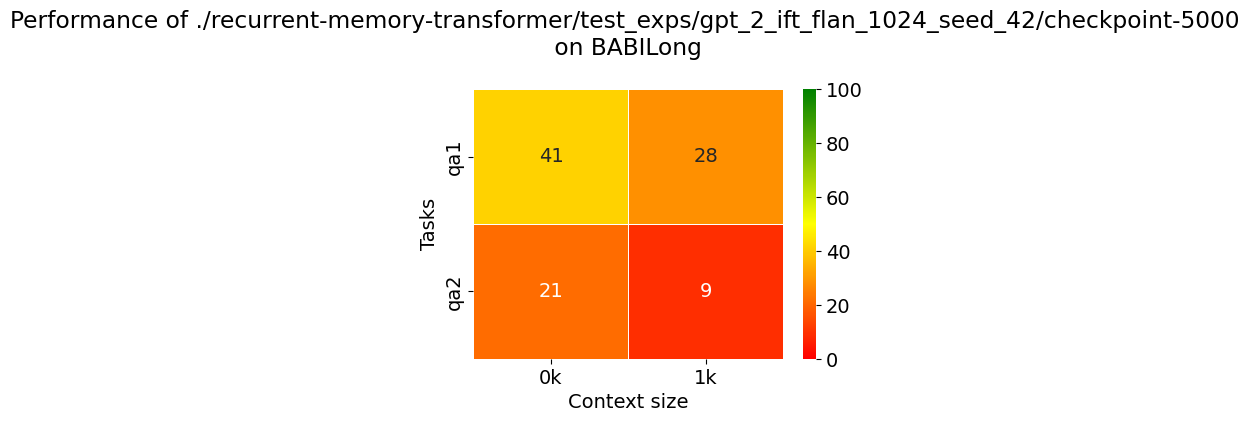

In [13]:
results_folder = './babilong_evals_test'
model_name = 'openai-community/gpt2'
#model_name = 'openai-community/rmt-ift-gpt2'
#model_name = 'vicgalle/gpt2-open-instruct-v1'
model_name = '../test_exps/gpt_2_ift_db15k_seed_42/checkpoint-5000'
model_name = '../test_exps/gpt_2_ift_db15k_long_seed_42/checkpoint-5000'
model_name = '../test_exps/gpt_2_ift_dolly_seed_42/checkpoint-10000'
model_name = '../test_exps/gpt_2_ift_dolly_left_seed_42/checkpoint-10000'
model_name = '../test_exps/gpt_2_ift_dolly15k_512_seed_42/checkpoint-44000'
model_name = '../test_exps/gpt_2_ift_alpaca_cleaned_512_seed_42/checkpoint-44000'
model_name = '../test_exps/gpt_2_ift_flan_1024_seed_42/checkpoint-7000'

#model_name = '../test_exps/gpt_2_ift_flan_1024_seed_42/checkpoint-8000'



prompt_name = 'instruction_yes_examples_yes_post_prompt_yes_chat_template_no'

results_folder = '../../babilong/babilong_evals'
model_name = './recurrent-memory-transformer/test_exps/gpt_2_ift_flan_1024_seed_42/checkpoint-5000'
#model_name = './gpt2_old'
prompt_name = 'instruction_yes_examples_yes_post_prompt_yes'


tasks = ['qa1', 'qa2']#, 'qa3', 'qa4', 'qa5']#, 'qa6', 'qa7', 'qa8', 'qa9', 'qa10']
lengths = ['0k', '1k']#, '2k', '4k', '8k', '16k', '32k']
accuracy = np.zeros((len(tasks), len(lengths)))
for j, task in enumerate(tasks):
    for i, ctx_length in enumerate(lengths):
        fname = f'./{results_folder}/{model_name}/{task}_{ctx_length}_{prompt_name}.csv'
        if not os.path.isfile(fname):
            print(f'No such file: {fname}')
            continue

        df = pd.read_csv(fname)

        if df['output'].dtype != object:
            df['output'] = df['output'].astype(str)
        df['output'] = df['output'].fillna('')


        df['correct'] = df.apply(lambda row: compare_answers(row['target'], row['output'],
                                                             row['question'], TASK_LABELS[task]
                                                             ), axis=1)
        score = df['correct'].sum()
        accuracy[j, i] = 100 * score / len(df) if len(df) > 0 else 0

# Set large font sizes for better visibility in the PDF
matplotlib.rc('font', size=14)

# Create a colormap for the heatmap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

# Create the heatmap
fig, ax = plt.subplots(figsize=(5, 3.5))  # Adjust the size as necessary
sns.heatmap(accuracy, cmap=cmap, vmin=0, vmax=100, annot=True, fmt=".0f",
            linewidths=.5, xticklabels=lengths, yticklabels=tasks, ax=ax)
ax.set_title(f'Performance of {model_name} \n on BABILong \n')
ax.set_xlabel('Context size')
ax.set_ylabel('Tasks')

# Save the figure to a PDF
# plt.savefig('all_tasks_performance.pdf', bbox_inches='tight')
plt.show()

In [9]:
!ls

Evaluate_RMT_on_BABILong.ipynb	       generate_long_instruct.ipynb
attention_maps.ipynb		       generate_long_instruct_from_ift.ipynb
attention_maps_tasks.ipynb	       qa1_single-supporting-fact_train.txt
babilong_evaluation_example.ipynb      rmt_demo_lm.ipynb
babilong_evaluation_example_ift.ipynb  run_gpt2_ift_flan.py


In [92]:
# extract results into table
results_folder = '../../babilong/babilong_evals'
#model_name = './recurrent-memory-transformer/test_exps/gpt_2_ift_flan_1024_seed_42/checkpoint-5000'
#model_name = './gpt2_old'
prompt_name = 'instruction_yes_examples_yes_post_prompt_yes_chat_template_no'

names = [
    "./gpt2",
    './test_exps/gpt_2_lora_ift_flan_1024_seed_42/checkpoint-1000',
    #'./test_exps/gpt_2_lora_ift_flan_1024_seed_42/checkpoint-2000',
    #'./test_exps/gpt_2_lora_ift_flan_1024_seed_42/checkpoint-3000',
    #'./test_exps/gpt_2_lora_ift_flan_1024_seed_42/checkpoint-4000',
    './test_exps/gpt_2_lora_ift_flan_1024_seed_42/checkpoint-5000',
    './test_exps/gpt_2_lora_ift_flan_1024_seed_42/checkpoint-10000',
    './test_exps/gpt_2_lora_ift_flan_1024_seed_42/checkpoint-15000',
    './test_exps/gpt_2_lora_ift_flan_1024_seed_42/checkpoint-20000',
    './test_exps/gpt_2_lora_ift_flan_1024_seed_42/checkpoint-25000',
    './test_exps/gpt_2_lora_ift_flan_1024_seed_42/checkpoint-30000',
    './test_exps/gpt_2_lora_ift_flan_1024_seed_42/checkpoint-35000',
    './test_exps/gpt_2_lora_ift_flan_1024_seed_42/checkpoint-40000',
    #"./gpt2",
    #'./recurrent-memory-transformer/test_exps/gpt_2_ift_flan_1024_seed_42/checkpoint-1000',
    #'./recurrent-memory-transformer/test_exps/gpt_2_ift_flan_1024_seed_42/checkpoint-2000',
    #'./recurrent-memory-transformer/test_exps/gpt_2_ift_flan_1024_seed_42/checkpoint-3000',
    #'./recurrent-memory-transformer/test_exps/gpt_2_ift_flan_1024_seed_42/checkpoint-4000',
    #'./recurrent-memory-transformer/test_exps/gpt_2_ift_flan_1024_seed_42/checkpoint-5000',
]
#gkuzmin/rmt_it/babilong/babilong_evals/test_exps/gpt_2_lora_ift_flan_1024_seed_42/checkpoint-1000
overall_results = {}
for model_name in names:
    overall_results[model_name] = {}
    tasks = ['qa1', 'qa2', 'qa4', 'qa5']#, 'qa3', 'qa4', 'qa5']#, 'qa6', 'qa7', 'qa8', 'qa9', 'qa10']
    lengths = ['0k', '1k']#, '2k', '4k', '8k', '16k', '32k']
    accuracy = np.zeros((len(tasks), len(lengths)))
    for j, task in enumerate(tasks):
        #overall_results[model_name][task] = {}
        for i, ctx_length in enumerate(lengths):
            fname = f'./{results_folder}/{model_name}/{task}_{ctx_length}_{prompt_name}.csv'
            if not os.path.isfile(fname):
                print(f'No such file: {fname}')
                continue
    
            df = pd.read_csv(fname)
    
            if df['output'].dtype != object:
                df['output'] = df['output'].astype(str)
            df['output'] = df['output'].fillna('')
    
    
            df['correct'] = df.apply(lambda row: compare_answers(row['target'], row['output'],
                                                                 row['question'], TASK_LABELS[task]
                                                                 ), axis=1)
            score = df['correct'].sum()
            overall_results[model_name][task + "_" + ctx_length] = float(np.round(100 * score / len(df) if len(df) > 0 else 0, 2))
            accuracy[j, i] = 100 * score / len(df) if len(df) > 0 else 0
    #print(accuracy)
    #overall_results[model_name][]
    # Set large font sizes for better visibility in the PDF
    """
    matplotlib.rc('font', size=14)
    
    # Create a colormap for the heatmap
    cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)
    
    # Create the heatmap
    fig, ax = plt.subplots(figsize=(5, 3.5))  # Adjust the size as necessary
    sns.heatmap(accuracy, cmap=cmap, vmin=0, vmax=100, annot=True, fmt=".0f",
                linewidths=.5, xticklabels=lengths, yticklabels=tasks, ax=ax)
    ax.set_title(f'Performance of {model_name} \n on BABILong \n')
    ax.set_xlabel('Context size')
    ax.set_ylabel('Tasks')
    
    # Save the figure to a PDF
    # plt.savefig('all_tasks_performance.pdf', bbox_inches='tight')
    plt.show()
    """

In [93]:
# flatten dict
#df = pd.json_normalize(overall_results[list(overall_results.keys())[0]], sep='_')
#new_res = {}
overall_results = {key.split("/")[-1]:value for key,value in overall_results.items()}

In [94]:
pd.DataFrame.from_dict(overall_results)

,gpt2,checkpoint-1000,checkpoint-5000,checkpoint-10000,checkpoint-15000,checkpoint-20000,checkpoint-25000,checkpoint-30000,checkpoint-35000,checkpoint-40000
qa1_0k,15.60,39.40,40.80,40.40,38.30,38.30,37.70,38.10,39.10,39.40
qa1_1k,23.00,32.20,31.90,34.50,35.10,34.70,34.20,32.30,33.40,36.20
qa2_0k,20.82,27.73,31.63,30.83,31.13,31.53,30.83,29.33,29.63,29.13
qa2_1k,19.92,19.62,22.22,24.52,22.82,21.92,24.02,22.52,20.82,22.42
qa4_0k,5.21,28.13,30.33,28.73,24.92,29.13,27.73,27.53,28.63,28.93
qa4_1k,7.31,15.72,12.81,15.92,10.41,13.31,15.12,15.32,14.91,10.31
qa5_0k,29.23,31.03,33.83,31.23,37.44,39.34,30.83,35.64,36.34,36.54
qa5_1k,32.10,34.50,38.42,42.53,40.82,44.43,40.32,40.12,37.11,37.91


In [101]:
# extract results into table
results_folder = '../../babilong/babilong_evals'
#model_name = './recurrent-memory-transformer/test_exps/gpt_2_ift_flan_1024_seed_42/checkpoint-5000'
#model_name = './gpt2_old'
prompt_name = 'instruction_yes_examples_yes_post_prompt_yes_chat_template_yes'

names = [
    "./microsoft/Phi-3.5-mini-instruct",
    './test_exps/phi35mini_ift_flan_1024_seed_42/checkpoint-2000',
    './test_exps/phi35mini_ift_flan_1024_seed_42/checkpoint-4000',
    './test_exps/phi35mini_ift_flan_1024_seed_42/checkpoint-6000',
    './test_exps/phi35mini_ift_flan_1024_seed_42/checkpoint-8000',
    './test_exps/phi35mini_ift_flan_1024_seed_42/checkpoint-12000',
    './test_exps/phi35mini_ift_flan_1024_seed_42/checkpoint-16000',
    './test_exps/phi35mini_ift_flan_1024_seed_42/checkpoint-20000',
    './test_exps/phi35mini_ift_flan_1024_seed_42/checkpoint-24000',
    #'./test_exps/gpt_2_lora_ift_flan_1024_seed_42/checkpoint-2000',
    #'./test_exps/gpt_2_lora_ift_flan_1024_seed_42/checkpoint-3000',
    #'./test_exps/gpt_2_lora_ift_flan_1024_seed_42/checkpoint-4000',
    #'./test_exps/gpt_2_lora_ift_flan_1024_seed_42/checkpoint-5000',
    #'./recurrent-memory-transformer/test_exps/gpt_2_ift_flan_1024_seed_42/checkpoint-5000',
]
#gkuzmin/rmt_it/babilong/babilong_evals/test_exps/gpt_2_lora_ift_flan_1024_seed_42/checkpoint-1000
overall_results = {}
for model_name in names:
    overall_results[model_name] = {}
    tasks = ['qa1', 'qa2', 'qa4', 'qa5']#, 'qa3', 'qa4', 'qa5']#, 'qa6', 'qa7', 'qa8', 'qa9', 'qa10']
    lengths = ['0k', '1k']#, '2k', '4k', '8k', '16k', '32k']
    accuracy = np.zeros((len(tasks), len(lengths)))
    for j, task in enumerate(tasks):
        #overall_results[model_name][task] = {}
        for i, ctx_length in enumerate(lengths):
            fname = f'./{results_folder}/{model_name}/{task}_{ctx_length}_{prompt_name}.csv'
            if not os.path.isfile(fname):
                print(f'No such file: {fname}')
                continue
    
            df = pd.read_csv(fname)
    
            if df['output'].dtype != object:
                df['output'] = df['output'].astype(str)
            df['output'] = df['output'].fillna('')
    
    
            df['correct'] = df.apply(lambda row: compare_answers(row['target'], row['output'],
                                                                 row['question'], TASK_LABELS[task]
                                                                 ), axis=1)
            score = df['correct'].sum()
            overall_results[model_name][task + "_" + ctx_length] = float(np.round(100 * score / len(df) if len(df) > 0 else 0, 2))
            accuracy[j, i] = 100 * score / len(df) if len(df) > 0 else 0
    #print(accuracy)
    #overall_results[model_name][]
    # Set large font sizes for better visibility in the PDF
    """
    matplotlib.rc('font', size=14)
    
    # Create a colormap for the heatmap
    cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)
    
    # Create the heatmap
    fig, ax = plt.subplots(figsize=(5, 3.5))  # Adjust the size as necessary
    sns.heatmap(accuracy, cmap=cmap, vmin=0, vmax=100, annot=True, fmt=".0f",
                linewidths=.5, xticklabels=lengths, yticklabels=tasks, ax=ax)
    ax.set_title(f'Performance of {model_name} \n on BABILong \n')
    ax.set_xlabel('Context size')
    ax.set_ylabel('Tasks')
    
    # Save the figure to a PDF
    # plt.savefig('all_tasks_performance.pdf', bbox_inches='tight')
    plt.show()
    """

No such file: ./../../babilong/babilong_evals/./test_exps/phi35mini_ift_flan_1024_seed_42/checkpoint-24000/qa1_0k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv
No such file: ./../../babilong/babilong_evals/./test_exps/phi35mini_ift_flan_1024_seed_42/checkpoint-24000/qa1_1k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv
No such file: ./../../babilong/babilong_evals/./test_exps/phi35mini_ift_flan_1024_seed_42/checkpoint-24000/qa2_0k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv
No such file: ./../../babilong/babilong_evals/./test_exps/phi35mini_ift_flan_1024_seed_42/checkpoint-24000/qa2_1k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv
No such file: ./../../babilong/babilong_evals/./test_exps/phi35mini_ift_flan_1024_seed_42/checkpoint-24000/qa4_0k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv
No such file: ./../../babilong/babilong_evals/./test_exps/phi35mini_ift_flan_1024_seed_42/check

In [102]:
# flatten dict
#df = pd.json_normalize(overall_results[list(overall_results.keys())[0]], sep='_')
#new_res = {}
overall_results = {key.split("/")[-1]:value for key,value in overall_results.items()}

In [103]:
pd.DataFrame.from_dict(overall_results)

,Phi-3.5-mini-instruct,checkpoint-2000,checkpoint-4000,checkpoint-6000,checkpoint-8000,checkpoint-12000,checkpoint-16000,checkpoint-20000,checkpoint-24000
qa1_0k,99.00,94.30,95.80,95.60,95.00,94.80,96.30,94.40,NaN
qa1_1k,91.20,77.90,78.60,73.00,78.70,79.10,75.70,75.30,NaN
qa2_0k,65.47,66.17,60.66,59.86,62.36,61.06,56.26,54.95,NaN
qa2_1k,57.56,46.25,45.45,45.25,42.54,43.84,42.94,41.74,NaN
qa4_0k,56.56,43.94,48.75,46.65,51.55,43.54,49.95,49.05,NaN
qa4_1k,60.26,38.54,52.55,51.65,55.66,46.05,51.55,55.86,NaN
qa5_0k,84.08,80.38,82.18,78.78,82.38,83.38,81.98,83.18,NaN
qa5_1k,85.16,72.02,77.23,74.42,78.34,76.93,73.52,80.44,NaN


In [146]:
# extract results into table
results_folder = '../../babilong/babilong_evals'
#model_name = './recurrent-memory-transformer/test_exps/gpt_2_ift_flan_1024_seed_42/checkpoint-5000'
#model_name = './gpt2_old'
prompt_name = 'instruction_yes_examples_yes_post_prompt_yes_chat_template_yes'

ift_dataset_path = "databricks-dolly-15k_ift_1024_seed_42"
mod_name = "Qwen/Qwen2.5-0.5B"
names = [
    f"./{mod_name}",
    f'./qwen_exps/{mod_name}/{ift_dataset_path}/checkpoint-100',
    f'./qwen_exps/{mod_name}/{ift_dataset_path}/checkpoint-300',
    f'./qwen_exps/{mod_name}/{ift_dataset_path}/checkpoint-500',
    f'./qwen_exps/{mod_name}/{ift_dataset_path}/checkpoint-1000',
    f'./qwen_exps/{mod_name}/{ift_dataset_path}/checkpoint-2000',
    f'./qwen_exps/{mod_name}/{ift_dataset_path}/checkpoint-6000',
    f'./qwen_exps/{mod_name}/{ift_dataset_path}/checkpoint-10000',
]

ift_dataset_path = "alpaca-cleaned_ift_1024_seed_42"
mod_name = "Qwen/Qwen2.5-0.5B"
names = [
    f"./{mod_name}",
    f'./qwen_exps/{mod_name}/{ift_dataset_path}/checkpoint-300',
    f'./qwen_exps/{mod_name}/{ift_dataset_path}/checkpoint-600',
    f'./qwen_exps/{mod_name}/{ift_dataset_path}/checkpoint-900',
    f'./qwen_exps/{mod_name}/{ift_dataset_path}/checkpoint-3000',
    f'./qwen_exps/{mod_name}/{ift_dataset_path}/checkpoint-12000',
    f'./qwen_exps/{mod_name}/{ift_dataset_path}/checkpoint-24000',
    f'./qwen_exps/{mod_name}/{ift_dataset_path}/checkpoint-29400',
]


ift_dataset_path = "flan_collection_ift_1024_seed_42"
mod_name = "Qwen/Qwen2.5-0.5B-Instruct"
names = [
    f"./{mod_name}",
    f'./qwen_exps/{mod_name}/{ift_dataset_path}/checkpoint-2000',
    f'./qwen_exps/{mod_name}/{ift_dataset_path}/checkpoint-4000',
    f'./qwen_exps/{mod_name}/{ift_dataset_path}/checkpoint-6000',
    f'./qwen_exps/{mod_name}/{ift_dataset_path}/checkpoint-10000',
    f'./qwen_exps/{mod_name}/{ift_dataset_path}/checkpoint-20000',
    f'./qwen_exps/{mod_name}/{ift_dataset_path}/checkpoint-30000',
    f'./qwen_exps/{mod_name}/{ift_dataset_path}/checkpoint-40000',
    f'./qwen_exps/{mod_name}/{ift_dataset_path}/checkpoint-50000',
    f'./qwen_exps/{mod_name}/{ift_dataset_path}/checkpoint-100000',
]

#gkuzmin/rmt_it/babilong/babilong_evals/test_exps/gpt_2_lora_ift_flan_1024_seed_42/checkpoint-1000
overall_results = {}
for model_name in names:
    overall_results[model_name] = {}
    tasks = ['qa1', 'qa2', 'qa4', 'qa5']#, 'qa3', 'qa4', 'qa5']#, 'qa6', 'qa7', 'qa8', 'qa9', 'qa10']
    lengths = ['0k', '1k']#, '2k', '4k', '8k', '16k', '32k']
    accuracy = np.zeros((len(tasks), len(lengths)))
    for j, task in enumerate(tasks):
        #overall_results[model_name][task] = {}
        for i, ctx_length in enumerate(lengths):
            fname = f'./{results_folder}/{model_name}/{task}_{ctx_length}_{prompt_name}.csv'
            if not os.path.isfile(fname):
                print(f'No such file: {fname}')
                continue
    
            df = pd.read_csv(fname)
    
            if df['output'].dtype != object:
                df['output'] = df['output'].astype(str)
            df['output'] = df['output'].fillna('')
    
    
            df['correct'] = df.apply(lambda row: compare_answers(row['target'], row['output'],
                                                                 row['question'], TASK_LABELS[task]
                                                                 ), axis=1)
            score = df['correct'].sum()
            overall_results[model_name][task + "_" + ctx_length] = float(np.round(100 * score / len(df) if len(df) > 0 else 0, 2))
            accuracy[j, i] = 100 * score / len(df) if len(df) > 0 else 0
    #print(accuracy)
overall_results = {key.split("/")[-1]:value for key,value in overall_results.items()}
pd.DataFrame.from_dict(overall_results)

,Qwen2.5-0.5B-Instruct,checkpoint-2000,checkpoint-4000,checkpoint-6000,checkpoint-10000,checkpoint-20000,checkpoint-30000,checkpoint-40000,checkpoint-50000,checkpoint-100000
qa1_0k,63.90,64.10,62.60,63.50,55.60,54.10,46.80,48.40,41.10,48.40
qa1_1k,64.20,45.20,51.70,48.80,43.10,49.80,42.50,44.10,43.40,37.60
qa2_0k,36.54,29.33,31.53,30.03,15.62,24.22,26.43,25.03,25.33,19.02
qa2_1k,31.93,18.12,25.33,23.42,17.52,22.02,19.12,15.82,18.62,19.62
qa4_0k,27.93,35.44,34.33,29.83,46.55,47.65,53.55,55.06,46.75,55.36
qa4_1k,21.92,27.03,28.23,28.73,29.93,29.63,31.63,37.54,35.34,32.63
qa5_0k,56.16,47.95,53.85,54.95,54.05,54.85,54.75,52.55,57.66,53.25
qa5_1k,56.77,40.62,48.95,53.76,48.35,50.75,45.64,46.34,50.25,50.95


## New results for 3 datasets with bigger models

In [174]:
# extract results into table
results_folder = '../../babilong/babilong_evals'
#model_name = './recurrent-memory-transformer/test_exps/gpt_2_ift_flan_1024_seed_42/checkpoint-5000'
#model_name = './gpt2_old'
prompt_name = 'instruction_yes_examples_yes_post_prompt_yes_chat_template_yes'

mod_name = "Qwen/Qwen2.5-0.5B-Instruct"

dataset_pathes = [
    "databricks-dolly-15k_ift_1024_seed_42",
    "alpaca-cleaned_ift_1024_seed_42",
    "unnatural-instructions-full_ift_1024_seed_42"
]

all_dfs = []
for dat_idx, ift_dataset_path in enumerate(dataset_pathes):
    #gkuzmin/rmt_it/babilong/babilong_evals/test_exps/gpt_2_lora_ift_flan_1024_seed_42/checkpoint-1000
    overall_results = {}
    dname = ift_dataset_path.split("-")[0]
    if "instruct" in mod_name.lower():
        prompt_name = 'instruction_yes_examples_yes_post_prompt_yes_chat_template_yes'
        all_names = [
            [f'./{mod_name}', f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-100', f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-500',],\
            [f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-800',],\
            [f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-100', f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-1000',]
        ]
    else:
        prompt_name = 'instruction_yes_examples_yes_post_prompt_yes_chat_template_no'
        all_names = [
            [f'./{mod_name}', f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-100', f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-500',],\
            [f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-800',],\
            [f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-100', f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-1000',]
        ]
    names = all_names[dat_idx]
    for model_name in names:
        overall_results[model_name] = {}
        tasks = ['qa1', 'qa2', 'qa4', 'qa5']#, 'qa3', 'qa4', 'qa5']#, 'qa6', 'qa7', 'qa8', 'qa9', 'qa10']
        lengths = ['0k', '1k']#, '2k', '4k', '8k', '16k', '32k']
        accuracy = np.zeros((len(tasks), len(lengths)))
        for j, task in enumerate(tasks):
            #overall_results[model_name][task] = {}
            for i, ctx_length in enumerate(lengths):
                fname = f'./{results_folder}/{model_name}/{task}_{ctx_length}_{prompt_name}.csv'
                if not os.path.isfile(fname):
                    print(f'No such file: {fname}')
                    continue
        
                df = pd.read_csv(fname)
        
                if df['output'].dtype != object:
                    df['output'] = df['output'].astype(str)
                df['output'] = df['output'].fillna('')
        
        
                df['correct'] = df.apply(lambda row: compare_answers(row['target'], row['output'],
                                                                     row['question'], TASK_LABELS[task]
                                                                     ), axis=1)
                score = df['correct'].sum()
                overall_results[model_name][task + "_" + ctx_length] = float(np.round(100 * score / len(df) if len(df) > 0 else 0, 2))
                accuracy[j, i] = 100 * score / len(df) if len(df) > 0 else 0
        #print(accuracy)
    overall_results = {dname + " " + key.split("/")[-1]:value for key,value in overall_results.items()}
    mod_df = pd.DataFrame.from_dict(overall_results)
    all_dfs.append(mod_df)
pd.concat(all_dfs, axis=1)

,databricks Qwen2.5-0.5B-Instruct,databricks checkpoint-100,databricks checkpoint-500,alpaca checkpoint-800,unnatural checkpoint-100,unnatural checkpoint-1000
qa1_0k,63.90,71.30,75.70,64.70,67.30,68.30
qa1_1k,64.20,58.60,55.70,59.60,62.00,61.40
qa2_0k,36.54,38.64,36.54,38.44,32.93,32.63
qa2_1k,31.93,28.63,27.03,29.33,27.63,27.13
qa4_0k,27.93,42.84,26.03,20.02,28.03,36.44
qa4_1k,21.92,37.64,23.92,34.23,22.62,39.14
qa5_0k,56.16,58.66,55.76,54.85,56.96,51.65
qa5_1k,56.77,53.56,48.75,59.98,59.98,56.87


In [163]:
# extract results into table
results_folder = '../../babilong/babilong_evals'
#model_name = './recurrent-memory-transformer/test_exps/gpt_2_ift_flan_1024_seed_42/checkpoint-5000'
#model_name = './gpt2_old'


mod_name = "Qwen/Qwen2.5-1.5B-Instruct"

dataset_pathes = [
    "databricks-dolly-15k_ift_1024_seed_42",
    "alpaca-cleaned_ift_1024_seed_42",
    "unnatural-instructions-full_ift_1024_seed_42"
]

all_dfs = []
for dat_idx, ift_dataset_path in enumerate(dataset_pathes):
    #gkuzmin/rmt_it/babilong/babilong_evals/test_exps/gpt_2_lora_ift_flan_1024_seed_42/checkpoint-1000
    overall_results = {}
    dname = ift_dataset_path.split("-")[0]
    if "instruct" in mod_name.lower():
        prompt_name = 'instruction_yes_examples_yes_post_prompt_yes_chat_template_yes'
        all_names = [
            [f'./{mod_name}', f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-100', f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-400',],\
            [f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-100',],\
            [f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-100', f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-1000',]
        ]
    else:
        prompt_name = 'instruction_yes_examples_yes_post_prompt_yes_chat_template_no'
        all_names = [
            [f'./{mod_name}', f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-100', f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-400',],\
            [f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-100',f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-500',],\
            [f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-100', f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-800',]
        ]
    names = all_names[dat_idx]
    for model_name in names:
        overall_results[model_name] = {}
        tasks = ['qa1', 'qa2', 'qa4', 'qa5']#, 'qa3', 'qa4', 'qa5']#, 'qa6', 'qa7', 'qa8', 'qa9', 'qa10']
        lengths = ['0k', '1k']#, '2k', '4k', '8k', '16k', '32k']
        accuracy = np.zeros((len(tasks), len(lengths)))
        for j, task in enumerate(tasks):
            #overall_results[model_name][task] = {}
            for i, ctx_length in enumerate(lengths):
                fname = f'./{results_folder}/{model_name}/{task}_{ctx_length}_{prompt_name}.csv'
                if not os.path.isfile(fname):
                    print(f'No such file: {fname}')
                    continue
        
                df = pd.read_csv(fname)
        
                if df['output'].dtype != object:
                    df['output'] = df['output'].astype(str)
                df['output'] = df['output'].fillna('')
        
        
                df['correct'] = df.apply(lambda row: compare_answers(row['target'], row['output'],
                                                                     row['question'], TASK_LABELS[task]
                                                                     ), axis=1)
                score = df['correct'].sum()
                overall_results[model_name][task + "_" + ctx_length] = float(np.round(100 * score / len(df) if len(df) > 0 else 0, 2))
                accuracy[j, i] = 100 * score / len(df) if len(df) > 0 else 0
        #print(accuracy)
    overall_results = {dname + " " + key.split("/")[-1]:value for key,value in overall_results.items()}
    mod_df = pd.DataFrame.from_dict(overall_results)
    all_dfs.append(mod_df)
pd.concat(all_dfs, axis=1)

No such file: ./../../babilong/babilong_evals/./qwen_exps/es_ablation/Qwen/Qwen2.5-1.5B-Instruct/alpaca-cleaned_ift_1024_seed_42/checkpoint-100/qa5_0k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv
No such file: ./../../babilong/babilong_evals/./qwen_exps/es_ablation/Qwen/Qwen2.5-1.5B-Instruct/alpaca-cleaned_ift_1024_seed_42/checkpoint-100/qa5_1k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv


,databricks Qwen2.5-1.5B-Instruct,databricks checkpoint-100,databricks checkpoint-400,alpaca checkpoint-100,unnatural checkpoint-100,unnatural checkpoint-1000
qa1_0k,73.90,71.90,67.10,68.70,72.60,74.00
qa1_1k,67.50,69.00,69.60,70.10,70.10,73.40
qa2_0k,48.75,46.45,41.24,46.75,45.15,44.14
qa2_1k,42.34,40.24,31.03,41.74,38.04,33.93
qa4_0k,44.14,31.33,32.13,30.03,28.63,37.24
qa4_1k,50.85,45.75,32.13,46.69,33.23,49.05
qa5_0k,72.27,64.56,60.76,NaN,55.26,59.36
qa5_1k,70.81,68.71,62.29,NaN,60.48,61.89


In [164]:
# extract results into table
results_folder = '../../babilong/babilong_evals'
#model_name = './recurrent-memory-transformer/test_exps/gpt_2_ift_flan_1024_seed_42/checkpoint-5000'
#model_name = './gpt2_old'


mod_name = "Qwen/Qwen2.5-3B-Instruct"

dataset_pathes = [
    "databricks-dolly-15k_ift_1024_seed_42",
    "alpaca-cleaned_ift_1024_seed_42",
    "unnatural-instructions-full_ift_1024_seed_42"
]

all_dfs = []
for dat_idx, ift_dataset_path in enumerate(dataset_pathes):
    #gkuzmin/rmt_it/babilong/babilong_evals/test_exps/gpt_2_lora_ift_flan_1024_seed_42/checkpoint-1000
    overall_results = {}
    dname = ift_dataset_path.split("-")[0]
    if "instruct" in mod_name.lower():
        prompt_name = 'instruction_yes_examples_yes_post_prompt_yes_chat_template_yes'
        all_names = [
            [f'./{mod_name}', f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-100', f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-300',],\
            [f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-100',],\
            [f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-100', f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-1000',]
        ]
    else:
        prompt_name = 'instruction_yes_examples_yes_post_prompt_yes_chat_template_no'
        all_names = [
            [f'./{mod_name}', f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-100', f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-200',],\
            [f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-100',f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-500',],\
            [f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-100', f'./qwen_exps/es_ablation/{mod_name}/{ift_dataset_path}/checkpoint-800',]
        ]
    names = all_names[dat_idx]
    for model_name in names:
        overall_results[model_name] = {}
        tasks = ['qa1', 'qa2', 'qa4', 'qa5']#, 'qa3', 'qa4', 'qa5']#, 'qa6', 'qa7', 'qa8', 'qa9', 'qa10']
        lengths = ['0k', '1k']#, '2k', '4k', '8k', '16k', '32k']
        accuracy = np.zeros((len(tasks), len(lengths)))
        for j, task in enumerate(tasks):
            #overall_results[model_name][task] = {}
            for i, ctx_length in enumerate(lengths):
                fname = f'./{results_folder}/{model_name}/{task}_{ctx_length}_{prompt_name}.csv'
                if not os.path.isfile(fname):
                    print(f'No such file: {fname}')
                    continue
        
                df = pd.read_csv(fname)
        
                if df['output'].dtype != object:
                    df['output'] = df['output'].astype(str)
                df['output'] = df['output'].fillna('')
        
        
                df['correct'] = df.apply(lambda row: compare_answers(row['target'], row['output'],
                                                                     row['question'], TASK_LABELS[task]
                                                                     ), axis=1)
                score = df['correct'].sum()
                overall_results[model_name][task + "_" + ctx_length] = float(np.round(100 * score / len(df) if len(df) > 0 else 0, 2))
                accuracy[j, i] = 100 * score / len(df) if len(df) > 0 else 0
        #print(accuracy)
    overall_results = {dname + " " + key.split("/")[-1]:value for key,value in overall_results.items()}
    mod_df = pd.DataFrame.from_dict(overall_results)
    all_dfs.append(mod_df)
pd.concat(all_dfs, axis=1)

No such file: ./../../babilong/babilong_evals/./qwen_exps/es_ablation/Qwen/Qwen2.5-3B-Instruct/alpaca-cleaned_ift_1024_seed_42/checkpoint-100/qa5_0k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv
No such file: ./../../babilong/babilong_evals/./qwen_exps/es_ablation/Qwen/Qwen2.5-3B-Instruct/alpaca-cleaned_ift_1024_seed_42/checkpoint-100/qa5_1k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv


,databricks Qwen2.5-3B-Instruct,databricks checkpoint-100,databricks checkpoint-300,alpaca checkpoint-100,unnatural checkpoint-100,unnatural checkpoint-1000
qa1_0k,91.60,84.80,84.50,88.50,81.50,82.10
qa1_1k,78.20,81.20,81.20,76.60,77.90,75.80
qa2_0k,49.45,48.55,50.05,49.75,47.55,42.64
qa2_1k,41.54,44.44,43.04,45.75,41.94,36.64
qa4_0k,45.35,49.95,47.95,46.75,46.35,48.65
qa4_1k,61.06,61.16,56.76,60.50,58.26,50.55
qa5_0k,77.48,80.28,82.28,NaN,78.28,78.28
qa5_1k,78.94,78.03,75.63,NaN,70.71,70.81


### Compare base Qwen2.5 models with RMT-tuned on Flan

In [52]:
# extract results into table
results_folder = '../../babilong/babilong_evals'
#model_name = './recurrent-memory-transformer/test_exps/gpt_2_ift_flan_1024_seed_42/checkpoint-5000'
#model_name = './gpt2_old'


mod_names = [
    #"Qwen/Qwen2.5-0.5B",
    #"Qwen/Qwen2.5-1.5B",
    #"Qwen/Qwen2.5-3B",
    "Qwen/Qwen2.5-0.5B-Instruct/runs/lm_no_st/flan/Qwen/Qwen2.5-0.5B-Instruct/linear_adamw_wd1e-03_4086-128-1x4096_mem5_bs32_regular_bptt-4_lora_freeze_from_cpt_0-1/run_2/model_best/pytorch_model.bin",
    "Qwen/Qwen2.5-0.5B-Instruct/runs/lm_no_st/flan/Qwen/Qwen2.5-0.5B-Instruct/linear_adamw_wd1e-03_8172-128-2x4096_mem5_bs32_regular_bptt-4_lora_freeze_from_cpt_1-2/run_2/model_best/pytorch_model.bin",
    "Qwen/Qwen2.5-0.5B-Instruct",
    "Qwen/Qwen2.5-1.5B-Instruct",
    "Qwen/Qwen2.5-3B-Instruct",
]
disp_names = [
    "RMT-4K-Qwen2.5-0.5B-Instruct",
    "RMT-4K-2Segm-Qwen2.5-0.5B-Instruct",
    "Qwen2.5-0.5B-Instruct",
    "Qwen2.5-1.5B-Instruct",
    "Qwen2.5-3B-Instruct",
]

all_dfs = []
for dat_idx, mod_name in enumerate(mod_names):
    #gkuzmin/rmt_it/babilong/babilong_evals/test_exps/gpt_2_lora_ift_flan_1024_seed_42/checkpoint-1000
    overall_results = {}
    #dname = ift_dataset_path.split("-")[0]
    if "instruct" in mod_name.lower():
        prompt_name = 'instruction_yes_examples_yes_post_prompt_yes_chat_template_yes'
        all_names = [
            [f'./{mod_name}']]
    else:
        prompt_name = 'instruction_yes_examples_yes_post_prompt_yes_chat_template_no'
        all_names = [
            [f'./{mod_name}']]
    names = all_names[0]
    for model_name in names:
        overall_results[disp_names[dat_idx]] = {}
        #tasks = ["qa2"]# ['qa1', 'qa2', 'qa4', 'qa5']#, 'qa3', 'qa4', 'qa5']#, 'qa6', 'qa7', 'qa8', 'qa9', 'qa10']
        tasks = ['qa1', 'qa2', 'qa4', 'qa5']
        lengths = ['0k', '1k', '2k', '4k', '8k', '16k', '32k', '64k']
        accuracy = np.zeros((len(tasks), len(lengths)))
        for j, task in enumerate(tasks):
            #overall_results[model_name][task] = {}
            for i, ctx_length in enumerate(lengths):
                fname = f'./{results_folder}/{model_name}/{task}_{ctx_length}_{prompt_name}.csv'
                if not os.path.isfile(fname):
                    print(f'No such file: {fname}')
                    continue
        
                df = pd.read_csv(fname)
        
                if df['output'].dtype != object:
                    df['output'] = df['output'].astype(str)
                df['output'] = df['output'].fillna('')
        
                if ctx_length == "32k":
                    df.dropna(inplace=True)
                    print(len(df))
                df['correct'] = df.apply(lambda row: compare_answers(row['target'], row['output'],
                                                                     row['question'], TASK_LABELS[task]
                                                                     ), axis=1)
                score = df['correct'].sum()
                #if model_name == "Qwen/Qwen2.5-0.5B-Instruct/runs/lm/flan/Qwen/Qwen2.5-0.5B-Instruct/linear_adamw_wd1e-03_4086-128-1x4096_mem5_bs32_regular_bptt-4_lora_freeze_from_cpt_0-1/run_2/model_best/model.safetensors":
                #    overall_results["RMT4k-Qwen2.5-0.5B-Instruct"][task + "_" + ctx_length] = float(np.round(100 * score / len(df) if len(df) > 0 else 0, 2))
                #else:
                overall_results[disp_names[dat_idx]][task + "_" + ctx_length] = float(np.round(100 * score / len(df) if len(df) > 0 else 0, 2))
                accuracy[j, i] = 100 * score / len(df) if len(df) > 0 else 0
        #print(accuracy)
    overall_results = {key.split("/")[-1]:value for key,value in overall_results.items()}
    mod_df = pd.DataFrame.from_dict(overall_results)
    all_dfs.append(mod_df)
pd.concat(all_dfs, axis=1)

1000
998
999
998
1000
999
999
999
1000
No such file: ./../../babilong/babilong_evals/./Qwen/Qwen2.5-0.5B-Instruct/qa1_64k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv
999
No such file: ./../../babilong/babilong_evals/./Qwen/Qwen2.5-0.5B-Instruct/qa2_64k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv
999
No such file: ./../../babilong/babilong_evals/./Qwen/Qwen2.5-0.5B-Instruct/qa4_64k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv
999
No such file: ./../../babilong/babilong_evals/./Qwen/Qwen2.5-0.5B-Instruct/qa5_64k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv
1000
No such file: ./../../babilong/babilong_evals/./Qwen/Qwen2.5-1.5B-Instruct/qa1_64k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv
999
No such file: ./../../babilong/babilong_evals/./Qwen/Qwen2.5-1.5B-Instruct/qa2_64k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv
999
No such file: ./../../babilong/babil

,RMT-4K-Qwen2.5-0.5B-Instruct,RMT-4K-2Segm-Qwen2.5-0.5B-Instruct,Qwen2.5-0.5B-Instruct,Qwen2.5-1.5B-Instruct,Qwen2.5-3B-Instruct
qa1_0k,30.20,63.60,63.90,73.90,91.60
qa1_1k,0.80,10.70,64.20,67.50,78.20
qa1_2k,0.20,1.20,60.80,65.60,76.20
qa1_4k,0.10,0.50,55.40,62.90,77.60
qa1_8k,0.00,0.60,50.10,63.60,74.30
qa1_16k,0.00,0.10,41.10,64.40,76.60
qa1_32k,0.00,0.00,38.10,59.00,76.20
qa1_64k,0.00,0.10,NaN,NaN,NaN
qa2_0k,32.43,35.34,36.54,48.75,49.45
qa2_1k,28.63,29.33,31.93,42.34,41.54


### Compare base Qwen2.5 models with RMT-tuned on LongDolly

In [51]:
# extract results into table
results_folder = '../../babilong/babilong_evals'
results_folder_rmt = "../babilong_evals"
#model_name = './recurrent-memory-transformer/test_exps/gpt_2_ift_flan_1024_seed_42/checkpoint-5000'
#model_name = './gpt2_old'


mod_names = [
    #"Qwen/Qwen2.5-0.5B",
    #"Qwen/Qwen2.5-1.5B",
    #"Qwen/Qwen2.5-3B",
    "Qwen/Qwen2.5-0.5B-Instruct/runs/lm_no_st/longdolly/Qwen/Qwen2.5-0.5B-Instruct/linear_adamw_wd1e-03_1004-128-1x1024_mem10_bs32_regular_bptt-4_lora_freeze_from_cpt_0-1/run_2/model_best/pytorch_model.bin",
    "Qwen/Qwen2.5-0.5B-Instruct/runs/lm_no_st/longdolly/Qwen/Qwen2.5-0.5B-Instruct/linear_adamw_wd1e-03_2008-128-2x1024_mem10_bs32_regular_bptt-4_lora_freeze_from_cpt_1-2/run_2/model_best/pytorch_model.bin",
    "Qwen/Qwen2.5-0.5B-Instruct/runs/lm_no_st/longdolly/Qwen/Qwen2.5-0.5B-Instruct/linear_adamw_wd1e-03_4016-128-4x1024_mem10_bs32_regular_bptt-4_lora_freeze_from_cpt_2-4/run_2/model_best/pytorch_model.bin",
    "Qwen/Qwen2.5-0.5B-Instruct/runs/lm_no_st/longdolly/Qwen/Qwen2.5-0.5B-Instruct/linear_adamw_wd1e-03_8032-128-8x1024_mem10_bs32_regular_bptt-4_lora_freeze_from_cpt_4-8/run_2/model_best/pytorch_model.bin",
    "Qwen/Qwen2.5-0.5B-Instruct",
    #"Qwen/Qwen2.5-1.5B-Instruct",
    #"Qwen/Qwen2.5-3B-Instruct",
]
disp_names = [
    "RMT-1K-LD-Qwen2.5-0.5B-Instruct",
    "RMT-1K-LD-2Segm-Qwen2.5-0.5B-Instruct",
    "RMT-1K-LD-4Segm-Qwen2.5-0.5B-Instruct",
    "RMT-1K-LD-8Segm-Qwen2.5-0.5B-Instruct",
    "Qwen2.5-0.5B-Instruct",
    #"Qwen2.5-1.5B-Instruct",
    #"Qwen2.5-3B-Instruct",
]

all_dfs = []
for dat_idx, mod_name in enumerate(mod_names):
    #gkuzmin/rmt_it/babilong/babilong_evals/test_exps/gpt_2_lora_ift_flan_1024_seed_42/checkpoint-1000
    overall_results = {}
    #dname = ift_dataset_path.split("-")[0]
    if "instruct" in mod_name.lower():
        prompt_name = 'instruction_yes_examples_yes_post_prompt_yes_chat_template_yes'
        all_names = [
            [f'./{mod_name}']]
    else:
        prompt_name = 'instruction_yes_examples_yes_post_prompt_yes_chat_template_no'
        all_names = [
            [f'./{mod_name}']]
    names = all_names[0]
    for model_name in names:
        overall_results[disp_names[dat_idx]] = {}
        tasks = ["qa2"]# ['qa1', 'qa2', 'qa4', 'qa5']#, 'qa3', 'qa4', 'qa5']#, 'qa6', 'qa7', 'qa8', 'qa9', 'qa10']
        #tasks = ['qa1', 'qa2', 'qa4', 'qa5']
        lengths = ['0k', '1k', '2k', '4k', '8k', '16k', '32k', '64k']
        accuracy = np.zeros((len(tasks), len(lengths)))
        for j, task in enumerate(tasks):
            #overall_results[model_name][task] = {}
            for i, ctx_length in enumerate(lengths):
                if "lm_no_st" in model_name:
                    fname = f'./{results_folder_rmt}/{model_name}/{task}_{ctx_length}_{prompt_name}.csv'
                else:
                    fname = f'./{results_folder}/{model_name}/{task}_{ctx_length}_{prompt_name}.csv'
                if not os.path.isfile(fname):
                    print(f'No such file: {fname}')
                    continue
        
                df = pd.read_csv(fname)
        
                if df['output'].dtype != object:
                    df['output'] = df['output'].astype(str)
                df['output'] = df['output'].fillna('')
        
                if ctx_length == "32k":
                    df.dropna(inplace=True)
                    print(len(df))
                df['correct'] = df.apply(lambda row: compare_answers(row['target'], row['output'],
                                                                     row['question'], TASK_LABELS[task]
                                                                     ), axis=1)
                score = df['correct'].sum()
                #if model_name == "Qwen/Qwen2.5-0.5B-Instruct/runs/lm/flan/Qwen/Qwen2.5-0.5B-Instruct/linear_adamw_wd1e-03_4086-128-1x4096_mem5_bs32_regular_bptt-4_lora_freeze_from_cpt_0-1/run_2/model_best/model.safetensors":
                #    overall_results["RMT4k-Qwen2.5-0.5B-Instruct"][task + "_" + ctx_length] = float(np.round(100 * score / len(df) if len(df) > 0 else 0, 2))
                #else:
                overall_results[disp_names[dat_idx]][task + "_" + ctx_length] = float(np.round(100 * score / len(df) if len(df) > 0 else 0, 2))
                accuracy[j, i] = 100 * score / len(df) if len(df) > 0 else 0
        #print(accuracy)
    overall_results = {key.split("/")[-1]:value for key,value in overall_results.items()}
    mod_df = pd.DataFrame.from_dict(overall_results)
    all_dfs.append(mod_df)
pd.concat(all_dfs, axis=1)

999
No such file: ./../babilong_evals/./Qwen/Qwen2.5-0.5B-Instruct/runs/lm_no_st/longdolly/Qwen/Qwen2.5-0.5B-Instruct/linear_adamw_wd1e-03_1004-128-1x1024_mem10_bs32_regular_bptt-4_lora_freeze_from_cpt_0-1/run_2/model_best/pytorch_model.bin/qa2_64k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv
999
No such file: ./../babilong_evals/./Qwen/Qwen2.5-0.5B-Instruct/runs/lm_no_st/longdolly/Qwen/Qwen2.5-0.5B-Instruct/linear_adamw_wd1e-03_2008-128-2x1024_mem10_bs32_regular_bptt-4_lora_freeze_from_cpt_1-2/run_2/model_best/pytorch_model.bin/qa2_64k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv
999
No such file: ./../babilong_evals/./Qwen/Qwen2.5-0.5B-Instruct/runs/lm_no_st/longdolly/Qwen/Qwen2.5-0.5B-Instruct/linear_adamw_wd1e-03_4016-128-4x1024_mem10_bs32_regular_bptt-4_lora_freeze_from_cpt_2-4/run_2/model_best/pytorch_model.bin/qa2_64k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv
999
No such file: ./../babilong_evals/./Qwen/Qwen2.5

,RMT-1K-LD-Qwen2.5-0.5B-Instruct,RMT-1K-LD-2Segm-Qwen2.5-0.5B-Instruct,RMT-1K-LD-4Segm-Qwen2.5-0.5B-Instruct,RMT-1K-LD-8Segm-Qwen2.5-0.5B-Instruct,Qwen2.5-0.5B-Instruct
qa2_0k,0.0,0.0,0.0,0.0,36.54
qa2_1k,0.1,0.1,0.0,0.0,31.93
qa2_2k,0.0,3.5,2.2,3.7,31.23
qa2_4k,0.0,1.9,0.3,1.2,26.23
qa2_8k,0.0,0.0,0.2,0.4,20.32
qa2_16k,0.0,0.0,0.0,0.0,15.52
qa2_32k,0.0,0.0,0.0,0.0,13.51


### Compare base Qwen2.5 models with RMT-tuned on LAMix

In [56]:
# extract results into table
results_folder = '../../babilong/babilong_evals'
results_folder_rmt = "../babilong_evals"
#model_name = './recurrent-memory-transformer/test_exps/gpt_2_ift_flan_1024_seed_42/checkpoint-5000'
#model_name = './gpt2_old'


mod_names = [
    #"Qwen/Qwen2.5-0.5B",
    #"Qwen/Qwen2.5-1.5B",
    #"Qwen/Qwen2.5-3B",
    "Qwen/Qwen2.5-0.5B-Instruct/runs/lm_no_st/LAMix/Qwen/Qwen2.5-0.5B-Instruct/linear_adamw_wd1e-03_6124-128-1x6144_mem10_bs32_regular_bptt-4_lora_freeze_from_cpt_0-1/run_2/model_best/pytorch_model.bin",
    "Qwen/Qwen2.5-0.5B-Instruct",
    #"Qwen/Qwen2.5-1.5B-Instruct",
    #"Qwen/Qwen2.5-3B-Instruct",
]
disp_names = [
    "RMT-6K-LAMix-Qwen2.5-0.5B-Instruct",
    "Qwen2.5-0.5B-Instruct",
    #"Qwen2.5-1.5B-Instruct",
    #"Qwen2.5-3B-Instruct",
]

all_dfs = []
for dat_idx, mod_name in enumerate(mod_names):
    #gkuzmin/rmt_it/babilong/babilong_evals/test_exps/gpt_2_lora_ift_flan_1024_seed_42/checkpoint-1000
    overall_results = {}
    #dname = ift_dataset_path.split("-")[0]
    if "instruct" in mod_name.lower():
        prompt_name = 'instruction_yes_examples_yes_post_prompt_yes_chat_template_yes'
        all_names = [
            [f'./{mod_name}']]
    else:
        prompt_name = 'instruction_yes_examples_yes_post_prompt_yes_chat_template_no'
        all_names = [
            [f'./{mod_name}']]
    names = all_names[0]
    for model_name in names:
        overall_results[disp_names[dat_idx]] = {}
        tasks = ["qa2"]# ['qa1', 'qa2', 'qa4', 'qa5']#, 'qa3', 'qa4', 'qa5']#, 'qa6', 'qa7', 'qa8', 'qa9', 'qa10']
        tasks = ['qa1', 'qa2', 'qa4', 'qa5']
        lengths = ['0k', '1k', '2k', '4k', '8k', '16k', '32k', '64k']
        accuracy = np.zeros((len(tasks), len(lengths)))
        for j, task in enumerate(tasks):
            #overall_results[model_name][task] = {}
            for i, ctx_length in enumerate(lengths):
                if "lm_no_st" in model_name:
                    fname = f'./{results_folder_rmt}/{model_name}/{task}_{ctx_length}_{prompt_name}.csv'
                else:
                    fname = f'./{results_folder}/{model_name}/{task}_{ctx_length}_{prompt_name}.csv'
                if not os.path.isfile(fname):
                    print(f'No such file: {fname}')
                    continue
        
                df = pd.read_csv(fname)
        
                if df['output'].dtype != object:
                    df['output'] = df['output'].astype(str)
                df['output'] = df['output'].fillna('')
        
                if ctx_length == "32k":
                    df.dropna(inplace=True)
                    print(len(df))
                df['correct'] = df.apply(lambda row: compare_answers(row['target'], row['output'],
                                                                     row['question'], TASK_LABELS[task]
                                                                     ), axis=1)
                score = df['correct'].sum()
                #if model_name == "Qwen/Qwen2.5-0.5B-Instruct/runs/lm/flan/Qwen/Qwen2.5-0.5B-Instruct/linear_adamw_wd1e-03_4086-128-1x4096_mem5_bs32_regular_bptt-4_lora_freeze_from_cpt_0-1/run_2/model_best/model.safetensors":
                #    overall_results["RMT4k-Qwen2.5-0.5B-Instruct"][task + "_" + ctx_length] = float(np.round(100 * score / len(df) if len(df) > 0 else 0, 2))
                #else:
                overall_results[disp_names[dat_idx]][task + "_" + ctx_length] = float(np.round(100 * score / len(df) if len(df) > 0 else 0, 2))
                accuracy[j, i] = 100 * score / len(df) if len(df) > 0 else 0
        #print(accuracy)
    overall_results = {key.split("/")[-1]:value for key,value in overall_results.items()}
    mod_df = pd.DataFrame.from_dict(overall_results)
    all_dfs.append(mod_df)
pd.concat(all_dfs, axis=1)

1000
999
999
999
1000
No such file: ./../../babilong/babilong_evals/./Qwen/Qwen2.5-0.5B-Instruct/qa1_64k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv
999
No such file: ./../../babilong/babilong_evals/./Qwen/Qwen2.5-0.5B-Instruct/qa2_64k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv
999
No such file: ./../../babilong/babilong_evals/./Qwen/Qwen2.5-0.5B-Instruct/qa4_64k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv
999
No such file: ./../../babilong/babilong_evals/./Qwen/Qwen2.5-0.5B-Instruct/qa5_64k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv


,RMT-6K-LAMix-Qwen2.5-0.5B-Instruct,Qwen2.5-0.5B-Instruct
qa1_0k,53.90,63.90
qa1_1k,36.90,64.20
qa1_2k,19.10,60.80
qa1_4k,9.20,55.40
qa1_8k,0.00,50.10
qa1_16k,0.00,41.10
qa1_32k,0.00,38.10
qa1_64k,0.00,NaN
qa2_0k,16.92,36.54
qa2_1k,9.61,31.93


### Compare base Qwen2.5 models with IFT ones on long datasets

In [64]:
# extract results into table
results_folder = '../../babilong/babilong_evals'
new_results_folder = '../../rmt_ift/babilong_evals'
#model_name = './recurrent-memory-transformer/test_exps/gpt_2_ift_flan_1024_seed_42/checkpoint-5000'
#model_name = './gpt2_old'


mod_names = [
    #"Qwen/Qwen2.5-0.5B",
    #"Qwen/Qwen2.5-1.5B",
    #"Qwen/Qwen2.5-3B",
    "qwen_exps/es_ablation/Qwen/Qwen2.5-0.5B-Instruct/dolly_15k_1024_ift_16384_seed_42/checkpoint-950",
    "qwen_exps/es_ablation/Qwen/Qwen2.5-0.5B-Instruct/LongAlign-10k_ift_16384_seed_42/checkpoint-700",
    "mergekit/test_LA_merge",
    "qwen_exps/es_ablation/Qwen/Qwen2.5-0.5B-Instruct/LongAlign_sg_16k_mix_ift_16384_seed_42/checkpoint-4400",
    "qwen_exps/es_ablation/Qwen/Qwen2.5-0.5B-Instruct/LongAlign_sg_16k_mix_ift_16384_seed_42/checkpoint-6800",
    "qwen_exps/es_ablation/Qwen/Qwen2.5-0.5B-Instruct/LongAlign_sg_16k_mix_ift_16384_seed_42/checkpoint-12000",
    "Qwen/Qwen2.5-0.5B-Instruct",
    #"Qwen/Qwen2.5-1.5B-Instruct",
    #"Qwen/Qwen2.5-3B-Instruct",
]
disp_names = [
    "LD-Qwen2.5-0.5B-Instruct",
    "LA-Qwen2.5-0.5B-Instruct",
    "LA-Merge-Qwen2.5-0.5B-Instruct",
    "LAMix-Qwen2.5-0.5B-Instruct-4400",
    "LAMix-Qwen2.5-0.5B-Instruct-6800",
    "LAMix-Qwen2.5-0.5B-Instruct-12000",
    "Qwen2.5-0.5B-Instruct",
    #"Qwen2.5-1.5B-Instruct",
    #"Qwen2.5-3B-Instruct",
]

all_dfs = []
for dat_idx, mod_name in enumerate(mod_names):
    #gkuzmin/rmt_it/babilong/babilong_evals/test_exps/gpt_2_lora_ift_flan_1024_seed_42/checkpoint-1000
    overall_results = {}
    #dname = ift_dataset_path.split("-")[0]
    if "instruct" in mod_name.lower() or "mergekit" in mod_name.lower():
        prompt_name = 'instruction_yes_examples_yes_post_prompt_yes_chat_template_yes'
        all_names = [
            [f'./{mod_name}']]
    else:
        prompt_name = 'instruction_yes_examples_yes_post_prompt_yes_chat_template_no'
        all_names = [
            [f'./{mod_name}']]
    names = all_names[0]
    for model_name in names:
        overall_results[disp_names[dat_idx]] = {}
        tasks = ["qa2"]# ['qa1', 'qa2', 'qa4', 'qa5']#, 'qa3', 'qa4', 'qa5']#, 'qa6', 'qa7', 'qa8', 'qa9', 'qa10']
        tasks = ['qa1', 'qa2', 'qa4', 'qa5']
        lengths = ['0k', '1k', '2k', '4k', '8k', '16k']#, '32k', '64k']
        accuracy = np.zeros((len(tasks), len(lengths)))
        for j, task in enumerate(tasks):
            #overall_results[model_name][task] = {}
            for i, ctx_length in enumerate(lengths):
                if "lm_no_st" in model_name:
                    fname = f'./{results_folder_rmt}/{model_name}/{task}_{ctx_length}_{prompt_name}.csv'
                elif "mix" in model_name or "mergekit" in model_name:
                    fname = f'./{new_results_folder}/{model_name}/{task}_{ctx_length}_{prompt_name}.csv'
                else:
                    fname = f'./{results_folder}/{model_name}/{task}_{ctx_length}_{prompt_name}.csv'
                if not os.path.isfile(fname):
                    print(f'No such file: {fname}')
                    continue
        
                df = pd.read_csv(fname)
        
                if df['output'].dtype != object:
                    df['output'] = df['output'].astype(str)
                df['output'] = df['output'].fillna('')
        
                if ctx_length == "32k":
                    df.dropna(inplace=True)
                    print(len(df))
                df['correct'] = df.apply(lambda row: compare_answers(row['target'], row['output'],
                                                                     row['question'], TASK_LABELS[task]
                                                                     ), axis=1)
                score = df['correct'].sum()
                #if model_name == "Qwen/Qwen2.5-0.5B-Instruct/runs/lm/flan/Qwen/Qwen2.5-0.5B-Instruct/linear_adamw_wd1e-03_4086-128-1x4096_mem5_bs32_regular_bptt-4_lora_freeze_from_cpt_0-1/run_2/model_best/model.safetensors":
                #    overall_results["RMT4k-Qwen2.5-0.5B-Instruct"][task + "_" + ctx_length] = float(np.round(100 * score / len(df) if len(df) > 0 else 0, 2))
                #else:
                overall_results[disp_names[dat_idx]][task + "_" + ctx_length] = float(np.round(100 * score / len(df) if len(df) > 0 else 0, 2))
                accuracy[j, i] = 100 * score / len(df) if len(df) > 0 else 0
        #print(accuracy)
    overall_results = {key.split("/")[-1]:value for key,value in overall_results.items()}
    mod_df = pd.DataFrame.from_dict(overall_results)
    all_dfs.append(mod_df)
pd.concat(all_dfs, axis=1)

No such file: ./../../rmt_ift/babilong_evals/./mergekit/test_LA_merge/qa5_0k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv
No such file: ./../../rmt_ift/babilong_evals/./mergekit/test_LA_merge/qa5_1k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv
No such file: ./../../rmt_ift/babilong_evals/./mergekit/test_LA_merge/qa5_2k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv
No such file: ./../../rmt_ift/babilong_evals/./mergekit/test_LA_merge/qa5_4k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv
No such file: ./../../rmt_ift/babilong_evals/./mergekit/test_LA_merge/qa5_8k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv
No such file: ./../../rmt_ift/babilong_evals/./mergekit/test_LA_merge/qa5_16k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv


,LD-Qwen2.5-0.5B-Instruct,LA-Qwen2.5-0.5B-Instruct,LA-Merge-Qwen2.5-0.5B-Instruct,LAMix-Qwen2.5-0.5B-Instruct-4400,LAMix-Qwen2.5-0.5B-Instruct-6800,LAMix-Qwen2.5-0.5B-Instruct-12000,Qwen2.5-0.5B-Instruct
qa1_0k,44.70,62.60,63.30,65.50,61.50,61.70,63.90
qa1_1k,48.60,59.90,61.20,61.00,60.40,62.70,64.20
qa1_2k,43.40,53.20,59.40,47.80,45.50,48.80,60.80
qa1_4k,30.90,47.80,52.40,45.90,43.60,44.90,55.40
qa1_8k,25.20,32.20,39.40,40.90,38.60,38.10,50.10
qa1_16k,27.70,27.80,24.40,34.90,32.80,32.00,41.10
qa2_0k,23.12,35.84,36.84,33.53,34.13,35.14,36.54
qa2_1k,26.73,20.42,31.73,26.33,25.13,24.92,31.93
qa2_2k,27.43,21.02,28.83,18.12,16.52,16.22,31.23
qa2_4k,24.72,24.92,26.13,16.92,16.22,16.42,26.23


### Compare results for LLama1b models after IFT

In [86]:
# extract results into table
results_folder = '../../babilong/babilong_evals'
results_folder = '../../rmt_ift/babilong_evals'
#model_name = './recurrent-memory-transformer/test_exps/gpt_2_ift_flan_1024_seed_42/checkpoint-5000'
#model_name = './gpt2_old'


mod_names = [
    "meta-llama/Llama-3.2-1B",
    "llama_non_it_exps/meta-llama/Llama-3.2-1B/databricks-dolly-15k_ift_1024_seed_42/checkpoint-2000",
    "llama_non_it_exps/meta-llama/Llama-3.2-1B/alpaca-cleaned_ift_1024_seed_42/checkpoint-7000",
    "llama_non_it_exps/meta-llama/Llama-3.2-1B/unnatural-instructions-full_ift_1024_seed_42/checkpoint-8000",
    "llama_non_it_exps/meta-llama/Llama-3.2-1B/hf_dataset_sharegpt_ift_1024_seed_42/checkpoint-30000",
    "llama_non_it_exps/meta-llama/Llama-3.2-1B/ultrachat_200k_flattened_ift_1024_seed_42/checkpoint-30000",
    "llama_non_it_exps/meta-llama/Llama-3.2-1B/flan_collection_ift_1024_seed_42/checkpoint-30000",
    "unsloth/Llama-3.2-1B-Instruct",
]
disp_names = [
    "Llama-3.2-1B",
    "Dolly-Llama-3.2-1B",
    "Alpaca-Llama-3.2-1B",
    "Unnat-Llama-3.2-1B",

    "SGpt-Llama-3.2-1B",
    "UC-Llama-3.2-1B",
    "FLAN-Llama-3.2-1B",
    
    "Llama-3.2-1B-IT",
]

all_dfs = []
for dat_idx, mod_name in enumerate(mod_names):
    #gkuzmin/rmt_it/babilong/babilong_evals/test_exps/gpt_2_lora_ift_flan_1024_seed_42/checkpoint-1000
    overall_results = {}
    #dname = ift_dataset_path.split("-")[0]
    if ("Llama-3.2-1B-Instruct".lower() in mod_name.lower()):
        prompt_name = 'instruction_yes_examples_yes_post_prompt_yes_chat_template_yes'
        all_names = [
            [f'./{mod_name}']]
    else:
        prompt_name = 'instruction_yes_examples_yes_post_prompt_yes_chat_template_no'
        all_names = [
            [f'./{mod_name}']]
    names = all_names[0]
    for model_name in names:
        overall_results[disp_names[dat_idx]] = {}
        tasks = ["qa2"]# ['qa1', 'qa2', 'qa4', 'qa5']#, 'qa3', 'qa4', 'qa5']#, 'qa6', 'qa7', 'qa8', 'qa9', 'qa10']
        tasks = ['qa1', 'qa2', 'qa4', 'qa5']
        lengths = ['0k', '1k', '2k', '4k', '8k', '16k']#, '32k', '64k']
        accuracy = np.zeros((len(tasks), len(lengths)))
        for j, task in enumerate(tasks):
            #overall_results[model_name][task] = {}
            for i, ctx_length in enumerate(lengths):
                if "lm_no_st" in model_name:
                    fname = f'./{results_folder_rmt}/{model_name}/{task}_{ctx_length}_{prompt_name}.csv'
                elif "mix" in model_name or "mergekit" in model_name:
                    fname = f'./{new_results_folder}/{model_name}/{task}_{ctx_length}_{prompt_name}.csv'
                else:
                    fname = f'./{results_folder}/{model_name}/{task}_{ctx_length}_{prompt_name}.csv'
                if not os.path.isfile(fname):
                    print(f'No such file: {fname}')
                    continue
        
                df = pd.read_csv(fname)
        
                if df['output'].dtype != object:
                    df['output'] = df['output'].astype(str)
                df['output'] = df['output'].fillna('')
        
                if ctx_length == "32k":
                    df.dropna(inplace=True)
                    print(len(df))
                df['correct'] = df.apply(lambda row: compare_answers(row['target'], row['output'],
                                                                     row['question'], TASK_LABELS[task]
                                                                     ), axis=1)
                score = df['correct'].sum()
                #if model_name == "Qwen/Qwen2.5-0.5B-Instruct/runs/lm/flan/Qwen/Qwen2.5-0.5B-Instruct/linear_adamw_wd1e-03_4086-128-1x4096_mem5_bs32_regular_bptt-4_lora_freeze_from_cpt_0-1/run_2/model_best/model.safetensors":
                #    overall_results["RMT4k-Qwen2.5-0.5B-Instruct"][task + "_" + ctx_length] = float(np.round(100 * score / len(df) if len(df) > 0 else 0, 2))
                #else:
                overall_results[disp_names[dat_idx]][task + "_" + ctx_length] = float(np.round(100 * score / len(df) if len(df) > 0 else 0, 2))
                accuracy[j, i] = 100 * score / len(df) if len(df) > 0 else 0
        #print(accuracy)
    overall_results = {key.split("/")[-1]:value for key,value in overall_results.items()}
    mod_df = pd.DataFrame.from_dict(overall_results)
    all_dfs.append(mod_df)
pd.concat(all_dfs, axis=1)

,Llama-3.2-1B,Dolly-Llama-3.2-1B,Alpaca-Llama-3.2-1B,Unnat-Llama-3.2-1B,SGpt-Llama-3.2-1B,UC-Llama-3.2-1B,FLAN-Llama-3.2-1B,Llama-3.2-1B-IT
qa1_0k,0.00,44.40,66.50,43.40,61.30,17.70,30.20,70.70
qa1_1k,2.90,5.50,62.10,10.70,60.20,14.60,21.10,66.50
qa1_2k,20.90,18.70,53.30,9.10,54.70,14.10,16.70,59.80
qa1_4k,41.20,50.80,48.30,4.70,33.40,28.40,15.30,57.50
qa1_8k,48.90,40.80,37.50,5.30,28.90,35.70,14.50,55.20
qa1_16k,38.90,36.50,26.00,5.30,23.20,33.50,12.40,45.40
qa2_0k,0.00,0.00,35.64,23.02,37.54,15.32,24.52,45.35
qa2_1k,6.31,1.80,25.83,7.31,27.53,30.13,1.60,35.34
qa2_2k,20.82,10.61,24.82,12.11,25.33,24.82,5.71,26.93
qa2_4k,24.92,26.73,21.62,5.91,23.02,22.82,7.61,20.02


In [89]:
# extract results into table
results_folder = '../../babilong/babilong_evals'
results_folder = '../../rmt_ift/babilong_evals'
#model_name = './recurrent-memory-transformer/test_exps/gpt_2_ift_flan_1024_seed_42/checkpoint-5000'
#model_name = './gpt2_old'


mod_names = [
    #"meta-llama/Llama-3.2-1B",
    "llama_non_it_exps/meta-llama/Llama-3.2-1B/databricks-dolly-15k_ift_1024_seed_42/checkpoint-2000",
    "llama_non_it_exps/meta-llama/Llama-3.2-1B/alpaca-cleaned_ift_1024_seed_42/checkpoint-7000",
    "llama_non_it_exps/meta-llama/Llama-3.2-1B/unnatural-instructions-full_ift_1024_seed_42/checkpoint-8000",
    "llama_non_it_exps/meta-llama/Llama-3.2-1B/hf_dataset_sharegpt_ift_1024_seed_42/checkpoint-30000",
    "llama_non_it_exps/meta-llama/Llama-3.2-1B/ultrachat_200k_flattened_ift_1024_seed_42/checkpoint-30000",
    "llama_non_it_exps/meta-llama/Llama-3.2-1B/flan_collection_ift_1024_seed_42/checkpoint-30000",
    "meta-llama/Llama-3.2-1B/runs/rmt_ift_from_base/flan_mix/meta-llama/Llama-3.2-1B/linear_adamw_wd1e-03_4076-128-1x4096_mem10_bs32_regular_bptt-4_lora_freeze_from_cpt_0-1/run_2/model_best/pytorch_model.bin",
    "unsloth/Llama-3.2-1B-Instruct",
]
disp_names = [
    #"Llama-3.2-1B",
    "Dolly-Llama-3.2-1B",
    "Alpaca-Llama-3.2-1B",
    "Unnat-Llama-3.2-1B",

    "SGpt-Llama-3.2-1B",
    "UC-Llama-3.2-1B",
    "FLAN-Llama-3.2-1B",
    "RMT-FLANMix-Llama-3.2-1B",
    
    "Llama-3.2-1B-IT",
]

all_dfs = []
for dat_idx, mod_name in enumerate(mod_names):
    #gkuzmin/rmt_it/babilong/babilong_evals/test_exps/gpt_2_lora_ift_flan_1024_seed_42/checkpoint-1000
    overall_results = {}
    #dname = ift_dataset_path.split("-")[0]
    #if ("Llama-3.2-1B-Instruct".lower() in mod_name.lower()):
    prompt_name = 'instruction_yes_examples_yes_post_prompt_yes_chat_template_yes'
    all_names = [
        [f'./{mod_name}']]
    #else:
    #    prompt_name = 'instruction_yes_examples_yes_post_prompt_yes_chat_template_no'
    #    all_names = [
    #        [f'./{mod_name}']]
    names = all_names[0]
    for model_name in names:
        overall_results[disp_names[dat_idx]] = {}
        tasks = ["qa2"]# ['qa1', 'qa2', 'qa4', 'qa5']#, 'qa3', 'qa4', 'qa5']#, 'qa6', 'qa7', 'qa8', 'qa9', 'qa10']
        tasks = ['qa1', 'qa2', 'qa4', 'qa5']
        lengths = ['0k', '1k', '2k', '4k', '8k', '16k']#, '32k', '64k']
        accuracy = np.zeros((len(tasks), len(lengths)))
        for j, task in enumerate(tasks):
            #overall_results[model_name][task] = {}
            for i, ctx_length in enumerate(lengths):
                if "lm_no_st" in model_name:
                    fname = f'./{results_folder_rmt}/{model_name}/{task}_{ctx_length}_{prompt_name}.csv'
                elif "mix" in model_name or "mergekit" in model_name:
                    fname = f'./{new_results_folder}/{model_name}/{task}_{ctx_length}_{prompt_name}.csv'
                else:
                    fname = f'./{results_folder}/{model_name}/{task}_{ctx_length}_{prompt_name}.csv'
                if not os.path.isfile(fname):
                    print(f'No such file: {fname}')
                    continue
        
                df = pd.read_csv(fname)
        
                if df['output'].dtype != object:
                    df['output'] = df['output'].astype(str)
                df['output'] = df['output'].fillna('')
        
                if ctx_length == "32k":
                    df.dropna(inplace=True)
                    print(len(df))
                df['correct'] = df.apply(lambda row: compare_answers(row['target'], row['output'],
                                                                     row['question'], TASK_LABELS[task]
                                                                     ), axis=1)
                score = df['correct'].sum()
                #if model_name == "Qwen/Qwen2.5-0.5B-Instruct/runs/lm/flan/Qwen/Qwen2.5-0.5B-Instruct/linear_adamw_wd1e-03_4086-128-1x4096_mem5_bs32_regular_bptt-4_lora_freeze_from_cpt_0-1/run_2/model_best/model.safetensors":
                #    overall_results["RMT4k-Qwen2.5-0.5B-Instruct"][task + "_" + ctx_length] = float(np.round(100 * score / len(df) if len(df) > 0 else 0, 2))
                #else:
                overall_results[disp_names[dat_idx]][task + "_" + ctx_length] = float(np.round(100 * score / len(df) if len(df) > 0 else 0, 2))
                accuracy[j, i] = 100 * score / len(df) if len(df) > 0 else 0
        #print(accuracy)
    overall_results = {key.split("/")[-1]:value for key,value in overall_results.items()}
    mod_df = pd.DataFrame.from_dict(overall_results)
    all_dfs.append(mod_df)
pd.concat(all_dfs, axis=1)

No such file: ./../../rmt_ift/babilong_evals/./meta-llama/Llama-3.2-1B/runs/rmt_ift_from_base/flan_mix/meta-llama/Llama-3.2-1B/linear_adamw_wd1e-03_4076-128-1x4096_mem10_bs32_regular_bptt-4_lora_freeze_from_cpt_0-1/run_2/model_best/pytorch_model.bin/qa1_4k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv
No such file: ./../../rmt_ift/babilong_evals/./meta-llama/Llama-3.2-1B/runs/rmt_ift_from_base/flan_mix/meta-llama/Llama-3.2-1B/linear_adamw_wd1e-03_4076-128-1x4096_mem10_bs32_regular_bptt-4_lora_freeze_from_cpt_0-1/run_2/model_best/pytorch_model.bin/qa1_8k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv
No such file: ./../../rmt_ift/babilong_evals/./meta-llama/Llama-3.2-1B/runs/rmt_ift_from_base/flan_mix/meta-llama/Llama-3.2-1B/linear_adamw_wd1e-03_4076-128-1x4096_mem10_bs32_regular_bptt-4_lora_freeze_from_cpt_0-1/run_2/model_best/pytorch_model.bin/qa1_16k_instruction_yes_examples_yes_post_prompt_yes_chat_template_yes.csv
No such file: ./../../rmt_i

,Dolly-Llama-3.2-1B,Alpaca-Llama-3.2-1B,Unnat-Llama-3.2-1B,SGpt-Llama-3.2-1B,UC-Llama-3.2-1B,FLAN-Llama-3.2-1B,RMT-FLANMix-Llama-3.2-1B,Llama-3.2-1B-IT
qa1_0k,66.90,67.10,64.30,63.40,63.70,54.50,56.30,70.70
qa1_1k,65.30,27.00,68.80,65.90,58.40,48.10,16.30,66.50
qa1_2k,59.20,14.50,67.80,61.90,52.10,45.50,21.13,59.80
qa1_4k,53.00,0.30,60.30,44.30,32.70,42.20,NaN,57.50
qa1_8k,33.50,0.00,41.30,29.20,34.70,38.30,NaN,55.20
qa1_16k,31.90,0.10,36.80,25.90,32.30,33.70,NaN,45.40
qa2_0k,44.94,43.14,39.84,37.54,43.54,36.54,40.24,45.35
qa2_1k,34.93,17.22,30.63,31.63,32.03,16.42,11.81,35.34
qa2_2k,34.83,15.72,30.73,31.13,30.53,20.02,11.21,26.93
qa2_4k,30.53,0.30,26.13,27.13,27.13,19.22,2.20,20.02


### Eval base vs LongAlign models on Babilong to find out if it works

In [215]:
# extract results into table
results_folder = '../../babilong/babilong_evals'
#model_name = './recurrent-memory-transformer/test_exps/gpt_2_ift_flan_1024_seed_42/checkpoint-5000'
#model_name = './gpt2_old'


mod_names = [
    #"Qwen/Qwen2.5-0.5B",
    #"Qwen/Qwen2.5-1.5B",
    #"Qwen/Qwen2.5-3B",
    "THUDM_no_chat/LongAlign-7B-64k-base",
    "THUDM_no_chat/LongAlign-7B-64k",
    "THUDM/LongAlign-6B-64k-base",
    "THUDM/LongAlign-6B-64k",
]

all_dfs = []
for dat_idx, mod_name in enumerate(mod_names):
    #gkuzmin/rmt_it/babilong/babilong_evals/test_exps/gpt_2_lora_ift_flan_1024_seed_42/checkpoint-1000
    overall_results = {}
    #dname = ift_dataset_path.split("-")[0]
    if "instruct" in mod_name.lower():
        prompt_name = 'instruction_yes_examples_yes_post_prompt_yes_chat_template_yes'
        all_names = [
            [f'./{mod_name}']]
    else:
        prompt_name = 'instruction_yes_examples_yes_post_prompt_yes_chat_template_no'
        all_names = [
            [f'./{mod_name}']]
    names = all_names[0]
    for model_name in names:
        overall_results[model_name] = {}
        tasks = ['qa1', 'qa2']#, 'qa4', 'qa5']#, 'qa3', 'qa4', 'qa5']#, 'qa6', 'qa7', 'qa8', 'qa9', 'qa10']
        lengths = ['0k', '1k', '2k', '4k', '8k', '16k', '32k']
        accuracy = np.zeros((len(tasks), len(lengths)))
        for j, task in enumerate(tasks):
            #overall_results[model_name][task] = {}
            for i, ctx_length in enumerate(lengths):
                fname = f'./{results_folder}/{model_name}/{task}_{ctx_length}_{prompt_name}.csv'
                if not os.path.isfile(fname):
                    print(f'No such file: {fname}')
                    continue
        
                df = pd.read_csv(fname)
        
                if df['output'].dtype != object:
                    df['output'] = df['output'].astype(str)
                df['output'] = df['output'].fillna('')
        
        
                df['correct'] = df.apply(lambda row: compare_answers(row['target'], row['output'],
                                                                     row['question'], TASK_LABELS[task]
                                                                     ), axis=1)
                score = df['correct'].sum()
                overall_results[model_name][task + "_" + ctx_length] = float(np.round(100 * score / len(df) if len(df) > 0 else 0, 2))
                accuracy[j, i] = 100 * score / len(df) if len(df) > 0 else 0
        #print(accuracy)
    overall_results = {key.split("/")[-1]:value for key,value in overall_results.items()}
    mod_df = pd.DataFrame.from_dict(overall_results)
    all_dfs.append(mod_df)
pd.concat(all_dfs, axis=1)

No such file: ./../../babilong/babilong_evals/./THUDM/LongAlign-6B-64k/qa1_2k_instruction_yes_examples_yes_post_prompt_yes_chat_template_no.csv
No such file: ./../../babilong/babilong_evals/./THUDM/LongAlign-6B-64k/qa1_4k_instruction_yes_examples_yes_post_prompt_yes_chat_template_no.csv
No such file: ./../../babilong/babilong_evals/./THUDM/LongAlign-6B-64k/qa1_8k_instruction_yes_examples_yes_post_prompt_yes_chat_template_no.csv
No such file: ./../../babilong/babilong_evals/./THUDM/LongAlign-6B-64k/qa1_16k_instruction_yes_examples_yes_post_prompt_yes_chat_template_no.csv
No such file: ./../../babilong/babilong_evals/./THUDM/LongAlign-6B-64k/qa1_32k_instruction_yes_examples_yes_post_prompt_yes_chat_template_no.csv
No such file: ./../../babilong/babilong_evals/./THUDM/LongAlign-6B-64k/qa2_0k_instruction_yes_examples_yes_post_prompt_yes_chat_template_no.csv
No such file: ./../../babilong/babilong_evals/./THUDM/LongAlign-6B-64k/qa2_1k_instruction_yes_examples_yes_post_prompt_yes_chat_templa

,LongAlign-7B-64k-base,LongAlign-7B-64k,LongAlign-6B-64k-base,LongAlign-6B-64k
qa1_0k,18.10,79.90,68.90,78.7
qa1_1k,31.50,1.40,73.00,79.5
qa1_2k,18.30,4.00,62.10,NaN
qa1_4k,24.10,13.20,58.20,NaN
qa1_8k,34.70,20.10,50.40,NaN
qa1_16k,39.80,35.50,45.70,NaN
qa1_32k,37.90,18.60,45.70,NaN
qa2_0k,25.93,2.20,21.62,NaN
qa2_1k,22.12,0.50,27.33,NaN
qa2_2k,16.52,3.10,26.13,NaN


In [107]:
# flatten dict
#df = pd.json_normalize(overall_results[list(overall_results.keys())[0]], sep='_')
#new_res = {}
overall_results = {key.split("/")[-1]:value for key,value in overall_results.items()}

In [108]:
pd.DataFrame.from_dict(overall_results)

,Qwen2.5-0.5B,checkpoint-100,checkpoint-300,checkpoint-500,checkpoint-1000,checkpoint-2000,checkpoint-6000,checkpoint-10000
qa1_0k,2.60,0.0,0.00,0.00,0.00,0.00,0.00,0.40
qa1_1k,45.80,0.0,6.10,0.80,16.70,1.50,4.60,4.40
qa2_0k,0.00,0.0,0.00,0.00,1.10,1.60,1.70,1.60
qa2_1k,14.81,0.1,4.00,0.10,5.71,4.40,3.20,5.81
qa4_0k,18.72,0.0,0.00,0.00,1.00,0.50,0.40,0.50
qa4_1k,29.63,0.0,2.30,0.80,12.51,6.71,2.80,5.31
qa5_0k,2.10,0.0,0.90,0.10,13.71,2.90,6.41,15.52
qa5_1k,43.73,0.5,11.33,2.61,27.68,8.83,13.14,23.67


In [56]:
overall_results

{'gpt2': {'qa1_0k': 15.7, 'qa1_1k': 23.3, 'qa2_0k': 21.12, 'qa2_1k': 19.72},
 'checkpoint-1000': {'qa1_0k': 38.1,
  'qa1_1k': 31.6,
  'qa2_0k': 24.72,
  'qa2_1k': 18.42},
 'checkpoint-2000': {'qa1_0k': 27.1,
  'qa1_1k': 31.7,
  'qa2_0k': 12.41,
  'qa2_1k': 18.32},
 'checkpoint-3000': {'qa1_0k': 39.1,
  'qa1_1k': 37.5,
  'qa2_0k': 20.42,
  'qa2_1k': 13.61},
 'checkpoint-4000': {'qa1_0k': 41.8,
  'qa1_1k': 25.5,
  'qa2_0k': 16.72,
  'qa2_1k': 6.11},
 'checkpoint-5000': {'qa1_0k': 41.4,
  'qa1_1k': 28.5,
  'qa2_0k': 21.22,
  'qa2_1k': 9.01},
 'checkpoint-6000': {'qa1_0k': 33.7,
  'qa1_1k': 23.0,
  'qa2_0k': 23.72,
  'qa2_1k': 15.72},
 'checkpoint-7000': {'qa1_0k': 31.8,
  'qa1_1k': 21.9,
  'qa2_0k': 24.22,
  'qa2_1k': 14.81},
 'checkpoint-8000': {'qa1_0k': 20.6,
  'qa1_1k': 15.6,
  'qa2_0k': 10.91,
  'qa2_1k': 4.0},
 'checkpoint-9000': {'qa1_0k': 30.9,
  'qa1_1k': 18.6,
  'qa2_0k': 24.72,
  'qa2_1k': 7.21},
 'checkpoint-10000': {'qa1_0k': 31.0,
  'qa1_1k': 15.6,
  'qa2_0k': 31.83,
  'qa2_

We have more examples with evaluation of various models in ./notebooks and ./scripts folders.

E.g. how to run models that are hosted on HuggingFace with default prompts `scripts/run_model_on_babilong.py`.

```bash
RESULTS_FOLDER="./babilong_evals"
DATASET_NAME="booydar/babilong-1k-samples"
MODEL_NAME="mistralai/Mistral-7B-Instruct-v0.2"
TASKS=("qa1" "qa2" "qa3" "qa4" "qa5")
LENGTHS=("0k" "1k" "2k" "4k" "8k" "16k" "32k")
USE_CHAT_TEMPLATE=true
USE_INSTRUCTION=true
USE_EXAMPLES=true
USE_POST_PROMPT=true
API_URL=""

echo running $MODEL_NAME on "${TASKS[@]}" with "${LENGTHS[@]}"

python scripts/run_model_on_babilong.py \
    --results_folder "$RESULTS_FOLDER" \
    --dataset_name "$DATASET_NAME" \
    --model_name "$MODEL_NAME" \
    --tasks "${TASKS[@]}" \
    --lengths "${LENGTHS[@]}" \
    $( [ "$USE_CHAT_TEMPLATE" == true ] && echo "--use_chat_template" ) \
    $( [ "$USE_INSTRUCTION" == true ] && echo "--use_instruction" ) \
    $( [ "$USE_EXAMPLES" == true ] && echo "--use_examples" ) \
    $( [ "$USE_POST_PROMPT" == true ] && echo "--use_post_prompt" ) \
    --api_url "$API_URL"
```

It is also possible to evaluate models that are running through API (e.g., llamacpp):
```bash
RESULTS_FOLDER="./babilong_evals"
DATASET_NAME="booydar/babilong"
MODEL_NAME="CohereForAI/c4ai-command-r-v01"
TASKS=("qa1" "qa2" "qa3" "qa4" "qa5")
LENGTHS=("64k" "128k")
USE_CHAT_TEMPLATE=true
USE_INSTRUCTION=true
USE_EXAMPLES=true
USE_POST_PROMPT=true
API_URL="http://localhost:8081/completion"

echo running $MODEL_NAME on "${TASKS[@]}" with "${LENGTHS[@]}"

python scripts/run_model_on_babilong.py \
    --results_folder "$RESULTS_FOLDER" \
    --dataset_name "$DATASET_NAME" \
    --model_name "$MODEL_NAME" \
    --tasks "${TASKS[@]}" \
    --lengths "${LENGTHS[@]}" \
    $( [ "$USE_CHAT_TEMPLATE" == true ] && echo "--use_chat_template" ) \
    $( [ "$USE_INSTRUCTION" == true ] && echo "--use_instruction" ) \
    $( [ "$USE_EXAMPLES" == true ] && echo "--use_examples" ) \
    $( [ "$USE_POST_PROMPT" == true ] && echo "--use_post_prompt" ) \
    --api_url "$API_URL"
```